# Revision audit: dataset, leakage, interpretability and timing analyses without retraining

This notebook answers the open reviewer questions on the paper *Standardised Comparison of Convolutional and Transformer Backbones for Brain Tumour MRI Classification under Perceptual-Hash Deduplication* that can be settled **without retraining any model**. Every number it produces is meant to go straight into the manuscript or its supplement.

**Questions answered**

| # | Reviewer question | Section |
|---|---|---|
| 1 | Images contributed and surviving deduplication per source; native resolution per source | 7, 9 |
| 2 | How many of the 1,123 multiclass removals were cross-source versus within-source | 9 |
| 3 | Cross-label near-duplicate collisions: count, cause (label conflict or hash false positive), label-aware deduplication | 11 |
| 4 | Outcome of the same pHash pass on the 3,253 binary images | 12 |
| 5 | Is the Hamming threshold of 5 adequate (independent pixel-correlation detector) | 13 |
| 6 | Train-test near-duplicate leakage in each track, and how test accuracy changes with the threshold | 14, 15 |
| 7 | Fraction of Grad-CAM energy outside the brain, per model and class (mean and SD) | 19 |
| 8 | Sensitivity of the Swin-Base map to the Grad-CAM target layer; attention rollout for ViT-B/16 | 19 |
| 9 | Inference-only masking test (background-only and brain-only images) | 20 |
| 10 | Latency **and throughput** with a variance measure and a stated warm-up | 21 |

**Skipped because they need retraining:** re-running the nine binary models on a deduplicated pool, and the background-only *training* ablation. Section 15 gives a no-retraining proxy for the first: the accuracy of the existing models on the test images that have no near-duplicate in training. Section 20 gives a proxy for the second: the trained models run on background-only images. Patient-level splitting is out of scope because the JPEG sources carry no patient identifiers.

**Approach.** The original data collection and the original greedy pHash pass are reproduced exactly (same folder walk, same `imagehash.phash`, same threshold), and the result is checked against the published class counts (2,000 / 1,304 / 1,401). The stratified 70/15/15 splits are reproduced with seed 42 and checked against the stored prediction files. All pairwise Hamming distances are computed once, so every threshold analysis is exact. The model-based analyses load the trained checkpoints, with no gradient updates. Timing uses randomly initialised copies of each architecture, because compute cost does not depend on the weights.

**Hardware.** GPU T4 x2. CPU cores handle image decoding and hashing in parallel. The model analyses run one model per GPU at a time from a shared queue. Timing uses one GPU, as in the original benchmark.

**Required Kaggle settings**
- Accelerator: **GPU T4 x2**.
- Input datasets, the same four used for training (the notebook searches `/kaggle/input` so the mount layout does not matter):
  `navoneel/brain-mri-images-for-brain-tumor-detection`, `ahmedhamada0/brain-tumor-detection`, `sartajbhuvaji/brain-tumor-classification-mri`, `moundir8/jun-cheng-brain-tumor-mri-dataset-jpg`.
- Input dataset of stored run artefacts: a folder per run named like `binary-detection-efficientnetb0/metrics/predictions_test.csv` (and `predictions_val.csv`). Without it, section 10 uses the reproduced splits and section 15 reports pool sizes only, without accuracies. The bundle `revision-audit-inputs.zip` prepared with this notebook contains these files for all 15 runs.
- Optional, for sections 17 to 20: the trained checkpoints (`final_*.pth` or `best_*.pth` from the original run outputs, or any state dict). Each checkpoint is matched to its run by parameter names and shapes, so file names do not matter. Runs without a checkpoint are skipped and listed.
- Internet: only needed if `imagehash` or `timm` is missing from the Kaggle image.

**Outputs in `/kaggle/working/`**

```text
plots/      every figure, as PNG
metrics/    every table as CSV, plus revision_audit_summary.json
logs/       revision_audit.log
outputs.zip everything above, created by the last cell
```

## 1. Setup: imports

Imports everything the notebook needs. `imagehash` and `timm` are installed only if they are missing, because the original training notebooks used them from the Kaggle image. Expected output: nothing, or one install line per missing package.

In [1]:
import importlib
import subprocess
import sys


def ensure(module_name, pip_name=None):
    try:
        return importlib.import_module(module_name)
    except ImportError:
        print(f"Installing {pip_name or module_name} (requires Internet)...", flush=True)
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", pip_name or module_name]
        )
        return importlib.import_module(module_name)


imagehash = ensure("imagehash", "ImageHash")
timm = ensure("timm")

import concurrent.futures
import json
import math
import os
import queue
import shutil
import threading
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import FileLink, display
from PIL import Image
from scipy import ndimage
from scipy.stats import spearmanr
from skimage.filters import threshold_otsu
from sklearn.model_selection import train_test_split
from torchvision import transforms
from torchvision.models import (
    densenet121,
    efficientnet_b0,
    inception_v3,
    mobilenet_v3_large,
    resnet50,
    swin_b,
    vgg16,
    vit_b_16,
)
from tqdm.auto import tqdm

## 2. Hardware check

Prints the GPUs and their memory, CPU cores, RAM and free disk, plus library versions, and stops with a clear message if two GPUs are not visible. The timing results in section 21 depend on the GPU model, so it is recorded here.

In [2]:
gpu_count = torch.cuda.device_count()
for index in range(gpu_count):
    props = torch.cuda.get_device_properties(index)
    print(f"GPU {index}: {props.name}, {props.total_memory / 1024**3:.1f} GB", flush=True)
memory = psutil.virtual_memory()
print(
    f"CPU cores: {os.cpu_count()} | RAM total {memory.total / 1e9:.1f} GB, available {memory.available / 1e9:.1f} GB"
)
print(f"Free disk in /kaggle/working: {shutil.disk_usage('/kaggle/working').free / 1e9:.1f} GB")
print(
    f"torch {torch.__version__} | timm {timm.__version__} | "
    f"imagehash {getattr(imagehash, '__version__', 'unknown')} | numpy {np.__version__}"
)
assert (
    gpu_count >= 2
), "Two GPUs are not visible: select 'GPU T4 x2' as the accelerator in the notebook settings."
DEVICES = [torch.device(f"cuda:{index}") for index in range(gpu_count)]

GPU 0: Tesla T4, 14.6 GB
GPU 1: Tesla T4, 14.6 GB
CPU cores: 4 | RAM total 33.7 GB, available 31.8 GB
Free disk in /kaggle/working: 20.9 GB
torch 2.11.0+cu128 | timm 1.0.29 | imagehash 4.3.2 | numpy 2.1.3


## 3. Configuration

All paths, thresholds and benchmark settings in one place. The dataset folders, file extensions, class order, seed and Hamming tolerance are copied exactly from the training notebooks, because reproducing their data collection and deduplication depends on them. `RUNS` lists the 15 trained runs with the architecture and input size each used. `PAPER_EFFICIENCY` holds the latency and throughput reported in the paper, for comparison in section 21.

In [3]:
SEED = 42
HAMMING_TOLERANCE = 5  # threshold of the original multiclass pass
THRESHOLDS = list(range(0, 13))  # Hamming thresholds examined in the sensitivity analyses
NCC_DUPLICATE = (
    0.98  # normalised cross-correlation at or above which two thumbnails are the same image
)
THUMB = 64  # thumbnail side used for the correlation detector
N_JOBS = os.cpu_count()
GRADCAM_BATCH = 16
LAT_WARMUP, LAT_ITERS = 10, 100  # same as the training notebooks
THR_BATCH, THR_WARMUP, THR_ITERS = 32, 3, 20  # same as the training notebooks
BENCH_REPEATS = 3
GALLERY_PAIRS = 24
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working")
PLOTS, METRICS, LOGS = WORK / "plots", WORK / "metrics", WORK / "logs"

DATASET_ROOTS = {
    "navoneel": "brain-mri-images-for-brain-tumor-detection",
    "ahmedhamada0": "brain-tumor-detection",
    "sartajbhuvaji": "brain-tumor-classification-mri",
    "moundir8": "jun-cheng-brain-tumor-mri-dataset-jpg",
}
SOURCE_NAMES = {
    "brain-mri-images-for-brain-tumor-detection": "Chakrabarty",
    "brain-tumor-detection": "Br35H",
    "brain-tumor-classification-mri": "Bhuvaji",
    "jun-cheng-brain-tumor-mri-dataset-jpg": "Cheng",
}
# Relative folders in the order the training notebooks walked them
BINARY_FOLDERS = {
    0: [("navoneel", "no"), ("ahmedhamada0", "no")],
    1: [("navoneel", "yes"), ("ahmedhamada0", "yes")],
}
MC_FOLDERS = {
    0: [
        ("sartajbhuvaji", "Testing/glioma_tumor"),
        ("sartajbhuvaji", "Training/glioma_tumor"),
        ("moundir8", "brain tumor mri dataset/2_glioma"),
    ],
    1: [
        ("sartajbhuvaji", "Testing/meningioma_tumor"),
        ("sartajbhuvaji", "Training/meningioma_tumor"),
        ("moundir8", "brain tumor mri dataset/1_meningioma"),
    ],
    2: [
        ("sartajbhuvaji", "Testing/pituitary_tumor"),
        ("sartajbhuvaji", "Training/pituitary_tumor"),
        ("moundir8", "brain tumor mri dataset/3_pituitary_tumor"),
    ],
}
EXTENSIONS = {"binary": (".jpg", ".jpeg", ".png", ".tif"), "multiclass": (".jpg",)}
CLASS_NAMES = {"binary": ["No Tumor", "Tumor"], "multiclass": ["Glioma", "Meningioma", "Pituitary"]}
EXPECTED_POOL = {"binary": 3253, "multiclass": 5828}
EXPECTED_MC_KEPT = {0: 2000, 1: 1304, 2: 1401}

RUNS = pd.DataFrame(
    [
        ("binary-detection-coatnet0", "binary", "CoAtNet-0", "coatnet0", 224),
        ("binary-detection-densenet121", "binary", "DenseNet121", "densenet121", 224),
        ("binary-detection-efficientnetb0", "binary", "EfficientNetB0", "efficientnetb0", 224),
        ("binary-detection-resnet50", "binary", "ResNet50", "resnet50", 224),
        ("binary-detection-inceptionv3", "binary", "InceptionV3", "inceptionv3", 299),
        ("binary-detection-swinbase", "binary", "Swin-Base", "swin_timm", 224),
        ("binary-detection-vit-b16", "binary", "ViT-B/16", "vit", 224),
        ("binary-detection-mobilenetv3-large", "binary", "MobileNetV3-Large", "mobilenetv3", 224),
        ("binary-detection-vgg16", "binary", "VGG16", "vgg16", 224),
        ("classification-swinbase", "multiclass", "Swin-Base", "swin_tv", 224),
        ("classification-coatnet0", "multiclass", "CoAtNet-0", "coatnet0", 224),
        ("classification-inceptionv3", "multiclass", "InceptionV3", "inceptionv3", 299),
        ("classification-efficientnetb0", "multiclass", "EfficientNetB0", "efficientnetb0", 224),
        ("classification-resnet50", "multiclass", "ResNet50", "resnet50", 224),
        ("classification-vit-b16", "multiclass", "ViT-B/16", "vit", 224),
    ],
    columns=["run", "task", "model", "arch", "img_size"],
)
# Paper values (latency mean ms, batched throughput img/s) for comparison in section 21
PAPER_EFFICIENCY = {
    "binary-detection-efficientnetb0": (10.757, 1364.24),
    "binary-detection-mobilenetv3-large": (8.084, 2408.52),
    "binary-detection-densenet121": (19.430, 629.80),
    "binary-detection-resnet50": (7.347, 771.21),
    "binary-detection-inceptionv3": (14.049, 514.15),
    "binary-detection-coatnet0": (13.909, 520.34),
    "binary-detection-vit-b16": (8.797, 286.88),
    "binary-detection-swinbase": (28.987, 195.63),
    "binary-detection-vgg16": (8.185, 338.15),
    "classification-efficientnetb0": (13.851, 1470.84),
    "classification-resnet50": (7.824, 791.58),
    "classification-inceptionv3": (14.150, 532.64),
    "classification-coatnet0": (13.228, 498.58),
    "classification-vit-b16": (8.390, 289.50),
    "classification-swinbase": (35.131, 202.41),
}

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.benchmark = True  # as in the training notebooks
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

## 4. Output folders and helpers

Creates `plots/`, `metrics/` and `logs/`, and defines the helpers used throughout:
- `log` prints with a timestamp and appends to the log file.
- `save_fig`, `save_table` and `save_json` show and save results.
- `popcount64` counts set bits in 64-bit hashes; it is a lookup table, so it works on any numpy version.
- `path_key` reduces a file path to `<dataset>/<relative path>`, so paths from the stored prediction files match this session even if Kaggle mounts the datasets elsewhere.

`RESULTS` collects the headline numbers for the final summary.

In [4]:
for folder in (PLOTS, METRICS, LOGS):
    folder.mkdir(parents=True, exist_ok=True)
LOG_FILE = LOGS / "revision_audit.log"
RESULTS = {}


def log(message):
    line = f"[{time.strftime('%H:%M:%S')}] {message}"
    print(line, flush=True)
    with open(LOG_FILE, "a") as handle:
        handle.write(line + "\n")


def save_fig(fig, name):
    fig.savefig(PLOTS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def save_table(frame, name, show=True):
    frame.to_csv(METRICS / f"{name}.csv", index=False)
    if show:
        display(frame)


def save_json(obj, name):
    with open(METRICS / f"{name}.json", "w") as handle:
        json.dump(
            obj,
            handle,
            indent=2,
            default=lambda value: value.item() if hasattr(value, "item") else str(value),
        )


_POPCOUNT = np.array([bin(value).count("1") for value in range(256)], dtype=np.uint8)


def popcount64(values):
    values = np.ascontiguousarray(values, dtype=np.uint64)
    return _POPCOUNT[values.view(np.uint8)].reshape(*values.shape, 8).sum(axis=-1, dtype=np.uint8)


def path_key(path):
    parts = Path(path).parts
    rest = parts[parts.index("input") + 1 :] if "input" in parts else parts
    if rest and rest[0] == "datasets":
        rest = rest[2:]
    return "/".join(rest)


def pairs_within(matrix, valid):
    # Number of pairs i < j at each distance 0..255, from the full symmetric matrix
    counts = np.bincount(matrix.ravel(), minlength=256).astype(np.int64)
    counts[0] -= int(valid.sum())  # self-pairs on the diagonal
    return np.cumsum(counts // 2)  # entry t = pairs at distance <= t


def find_dataset_root(slug):
    candidates = sorted(path for path in INPUT.rglob(slug) if path.is_dir())
    assert candidates, f"Dataset '{slug}' is not attached: add it as an input to this notebook."
    return candidates[0]

## 5. Data collection

Rebuilds the binary pool (3,253 images) and the multiclass pool (5,828 images) exactly as the training notebooks did: the same folders, in the same order, with the same file extensions and the same labels. Each image also gets its source collection (Chakrabarty, Br35H, Bhuvaji, Cheng) and, for Bhuvaji, its original Training or Testing folder. The pool sizes are checked against the paper. Expected output: two source-by-class tables.

In [5]:
ROOTS = {owner: find_dataset_root(slug) for owner, slug in DATASET_ROOTS.items()}
for owner, root in ROOTS.items():
    log(f"{owner}: {root}")


def collect(folders, label, extensions):
    items = []
    for owner, relative in folders:
        for root, _, files in os.walk(ROOTS[owner] / relative):
            for name in files:
                if name.lower().endswith(extensions):
                    items.append((os.path.join(root, name), label))
    return items


def build_pool(task, folder_map):
    rows = []
    for label in sorted(folder_map):
        rows += collect(folder_map[label], label, EXTENSIONS[task])
    frame = pd.DataFrame(rows, columns=["path", "label"])
    frame["key"] = frame["path"].map(path_key)
    frame["source"] = frame["key"].map(lambda key: SOURCE_NAMES.get(key.split("/")[0], "Unknown"))
    frame["subset"] = np.where(
        frame["source"] == "Bhuvaji",
        frame["key"].map(lambda key: key.split("/")[1]),
        frame["source"],
    )
    frame["class_name"] = frame["label"].map(dict(enumerate(CLASS_NAMES[task])))
    return frame


POOLS = {
    "binary": build_pool("binary", BINARY_FOLDERS),
    "multiclass": build_pool("multiclass", MC_FOLDERS),
}
for task, frame in POOLS.items():
    status = "matches" if len(frame) == EXPECTED_POOL[task] else "DOES NOT MATCH"
    log(f"{task}: {len(frame)} images ({status} the paper's {EXPECTED_POOL[task]})")
    display(pd.crosstab(frame["subset"], frame["class_name"], margins=True))

[10:11:26] navoneel: /kaggle/input/datasets/navoneel/brain-mri-images-for-brain-tumor-detection
[10:11:26] ahmedhamada0: /kaggle/input/datasets/ahmedhamada0/brain-tumor-detection
[10:11:26] sartajbhuvaji: /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri
[10:11:26] moundir8: /kaggle/input/datasets/moundir8/jun-cheng-brain-tumor-mri-dataset-jpg
[10:11:26] binary: 3253 images (matches the paper's 3253)


class_name,No Tumor,Tumor,All
subset,,,
Br35H,1500,1500,3000
Chakrabarty,98,155,253
All,1598,1655,3253


[10:11:26] multiclass: 5828 images (matches the paper's 5828)


class_name,Glioma,Meningioma,Pituitary,All
subset,,,,
Cheng,1426,708,930,3064
Testing,100,115,74,289
Training,826,822,827,2475
All,2352,1645,1831,5828


## 6. Decode every image once: size, perceptual hash and thumbnail

Opens each image once, in parallel across all CPU cores, and records:
- its native width, height and colour mode;
- its 64-bit pHash, computed exactly as in training (`imagehash.phash` on the RGB-converted image) and stored as an unsigned 64-bit integer;
- a 64x64 greyscale thumbnail for the independent correlation-based duplicate detector.

Images that fail to open get no hash; the original pass skipped them too. Expected output: a progress bar per pool and a failure count, which should be zero.

In [6]:
def describe_image(path):
    try:
        with Image.open(path) as img:
            width, height, mode = img.size[0], img.size[1], img.mode
            rgb = img.convert("RGB")
        bits = np.packbits(imagehash.phash(rgb).hash.flatten().astype(np.uint8))
        hash_value = int.from_bytes(bits.tobytes(), "big")
        thumb = np.asarray(rgb.convert("L").resize((THUMB, THUMB), Image.BILINEAR), dtype=np.uint8)
        return width, height, mode, hash_value, thumb, True
    except Exception as exc:
        print(f"Error reading {path}: {exc}", flush=True)
        return 0, 0, "", 0, np.zeros((THUMB, THUMB), np.uint8), False


HASHES, THUMBS, VALID = {}, {}, {}
for task, frame in POOLS.items():
    start = time.perf_counter()
    with concurrent.futures.ProcessPoolExecutor(max_workers=N_JOBS) as pool:
        described = list(
            tqdm(
                pool.map(describe_image, frame["path"], chunksize=16),
                total=len(frame),
                desc=f"Decoding {task}",
            )
        )
    frame["width"] = [item[0] for item in described]
    frame["height"] = [item[1] for item in described]
    frame["mode"] = [item[2] for item in described]
    HASHES[task] = np.array([item[3] for item in described], dtype=np.uint64)
    THUMBS[task] = np.stack([item[4] for item in described])
    VALID[task] = np.array([item[5] for item in described])
    elapsed = time.perf_counter() - start
    log(
        f"{task}: decoded {len(frame)} images in {elapsed:.1f}s ({len(frame) / elapsed:.0f} img/s), "
        f"{(~VALID[task]).sum()} failures"
    )

Decoding binary:   0%|          | 0/3253 [00:00<?, ?it/s]

[10:11:34] binary: decoded 3253 images in 7.9s (412 img/s), 0 failures


Decoding multiclass:   0%|          | 0/5828 [00:00<?, ?it/s]

[10:11:54] multiclass: decoded 5828 images in 20.2s (289 img/s), 0 failures


## 7. Provenance and native resolution per source

Answers the provenance comment and fills the "native resolution" column the paper could only give as "Variable". For each source (with Bhuvaji split into its Training and Testing folders) it reports the images contributed, the counts by class, and the native size statistics: mean and SD of width and height, the minimum and maximum, the most common size and the share of images at that size. A width-height scatter shows how each source is framed. Expected output: one table and one figure.

,task,source,subset,images,n_No Tumor,n_Tumor,width_mean,width_sd,height_mean,height_sd,width_min,width_max,height_min,height_max,modal_size,modal_share_pct,distinct_sizes,n_Glioma,n_Meningioma,n_Pituitary
0,binary,Chakrabarty,Chakrabarty,253,98.0,155.0,354.2,217.1,386.0,213.1,150,1920,168,1427,225x225,7.1,184,NaN,NaN,NaN
1,binary,Br35H,Br35H,3000,1500.0,1500.0,325.2,174.4,352.8,182.8,150,1920,167,1427,225x225,10.9,291,NaN,NaN,NaN
2,multiclass,Bhuvaji,Testing,289,NaN,NaN,422.9,235.3,435.4,222.6,174,1358,167,1322,512x512,11.1,184,100.0,115.0,74.0
3,multiclass,Bhuvaji,Training,2475,NaN,NaN,500.9,66.5,501.9,64.1,180,1365,202,1427,512x512,93.1,137,826.0,822.0,827.0
4,multiclass,Cheng,Cheng,3064,NaN,NaN,510.7,17.9,510.7,17.9,256,512,256,512,512x512,99.5,2,1426.0,708.0,930.0


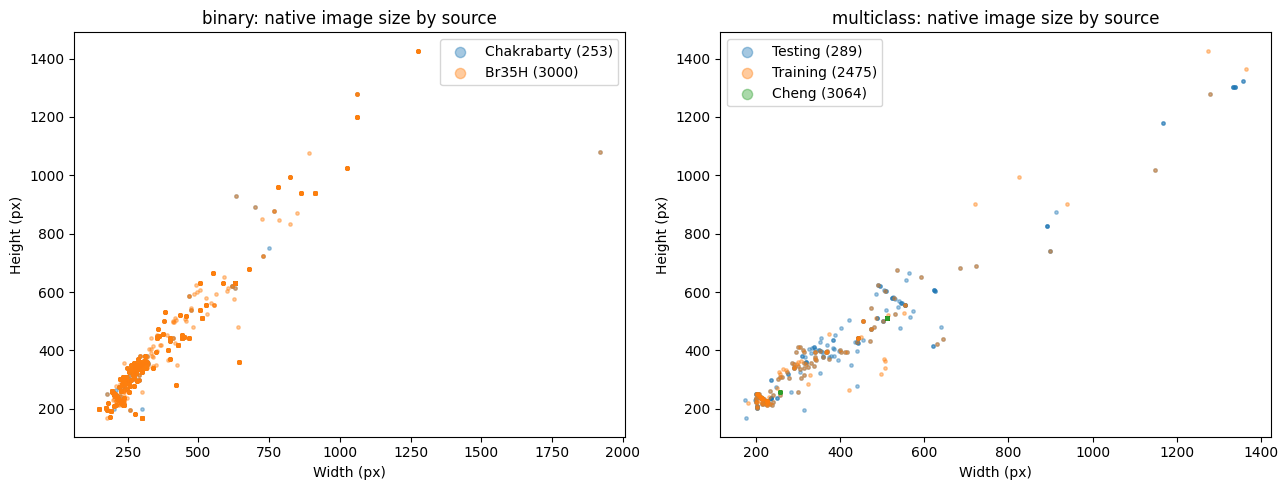

In [7]:
def resolution_table(task):
    frame = POOLS[task]
    rows = []
    for subset, group in frame.groupby("subset", sort=False):
        sizes = group["width"].astype(str) + "x" + group["height"].astype(str)
        modal = sizes.value_counts()
        row = {
            "task": task,
            "source": group["source"].iloc[0],
            "subset": subset,
            "images": len(group),
        }
        row.update(
            {f"n_{name}": int((group["class_name"] == name).sum()) for name in CLASS_NAMES[task]}
        )
        row.update(
            {
                "width_mean": group["width"].mean(),
                "width_sd": group["width"].std(),
                "height_mean": group["height"].mean(),
                "height_sd": group["height"].std(),
                "width_min": group["width"].min(),
                "width_max": group["width"].max(),
                "height_min": group["height"].min(),
                "height_max": group["height"].max(),
                "modal_size": modal.index[0],
                "modal_share_pct": 100 * modal.iloc[0] / len(group),
                "distinct_sizes": len(modal),
            }
        )
        rows.append(row)
    return pd.DataFrame(rows)


provenance = pd.concat([resolution_table(task) for task in POOLS], ignore_index=True)
save_table(provenance.round(1), "provenance_native_resolution")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, (task, frame) in zip(axes, POOLS.items()):
    for subset, group in frame.groupby("subset", sort=False):
        axis.scatter(
            group["width"], group["height"], s=6, alpha=0.4, label=f"{subset} ({len(group)})"
        )
    axis.set(
        title=f"{task}: native image size by source", xlabel="Width (px)", ylabel="Height (px)"
    )
    axis.legend(markerscale=3)
fig.tight_layout()
save_fig(fig, "01_native_size_by_source")

## 8. Pairwise Hamming distances

Computes the Hamming distance between every pair of pHashes in each pool, using XOR and a bit count, in row blocks. The result is a full `uint8` matrix: 34 MB for the multiclass pool and 11 MB for the binary pool. Every later threshold analysis reads this one matrix, so results are exact at every threshold. Images whose hash failed get a distance of 255, so they never match anything.

In [8]:
def hamming_matrix(hashes, valid, desc):
    count = len(hashes)
    matrix = np.empty((count, count), dtype=np.uint8)
    for start in tqdm(range(0, count, 512), desc=desc):
        matrix[start : start + 512] = popcount64(
            hashes[start : start + 512, None] ^ hashes[None, :]
        )
    matrix[~valid, :] = 255
    matrix[:, ~valid] = 255
    return matrix


DIST = {task: hamming_matrix(HASHES[task], VALID[task], f"Hamming {task}") for task in POOLS}
PAIRS_WITHIN = {task: pairs_within(matrix, VALID[task]) for task, matrix in DIST.items()}
for task, cumulative in PAIRS_WITHIN.items():
    log(
        f"{task}: {cumulative[-1]:,} pairs; pairs at distance <= {HAMMING_TOLERANCE}: {cumulative[HAMMING_TOLERANCE]:,}"
    )

Hamming binary:   0%|          | 0/7 [00:00<?, ?it/s]

Hamming multiclass:   0%|          | 0/12 [00:00<?, ?it/s]

[10:11:57] binary: 5,289,378 pairs; pairs at distance <= 5: 6,398
[10:11:57] multiclass: 16,979,878 pairs; pairs at distance <= 5: 1,623


## 9. Reproduce the original multiclass deduplication and break down the removals

`greedy_dedup` copies the training notebooks' rule. It visits images in collection order and keeps an image only if its distance to **every** image already kept is greater than the tolerance. For each removed image it also records the nearest kept image that caused the removal.

The reproduction is checked against the published per-class counts (2,000 / 1,304 / 1,401, total 4,705). Each removal is then classified as:
- **within-source or cross-source**: whether the nearest kept image came from the same collection;
- **same-label or cross-label**: whether it carried the same class.

Expected output: a verification line, the survival table (before, after and removed for each source and class), and the removal-type table. These answer the provenance comment and the cross-source question directly.

In [9]:
def greedy_dedup(matrix, valid, tolerance, labels=None):
    count = len(matrix)
    kept, nearest, nearest_distance = [], np.full(count, -1), np.full(count, 255)
    kept_by_label = {}
    for index in range(count):
        if not valid[index]:
            continue
        pool = kept if labels is None else kept_by_label.setdefault(labels[index], [])
        if pool:
            row = matrix[index, pool]
            best = int(row.argmin())
            if row[best] <= tolerance:
                nearest[index], nearest_distance[index] = pool[best], int(row[best])
                continue
        pool.append(index)
        if labels is not None:
            kept.append(index)
    keep = np.zeros(count, dtype=bool)
    keep[kept] = True
    return keep, nearest, nearest_distance


def removal_breakdown(task, keep, nearest):
    frame = POOLS[task]
    removed = np.flatnonzero(~keep & VALID[task])
    partner = nearest[removed]
    table = pd.DataFrame(
        {
            "class_name": frame["class_name"].values[removed],
            "source": frame["subset"].values[removed],
            "kept_partner_source": frame["subset"].values[partner],
            "origin": np.where(
                frame["source"].values[removed] == frame["source"].values[partner],
                "within-source",
                "cross-source",
            ),
            "label": np.where(
                frame["label"].values[removed] == frame["label"].values[partner],
                "same-label",
                "cross-label",
            ),
        }
    )
    return table


mc = POOLS["multiclass"]
MC_KEEP, MC_NEAREST, MC_NEAREST_D = greedy_dedup(
    DIST["multiclass"], VALID["multiclass"], HAMMING_TOLERANCE
)
kept_counts = mc.loc[MC_KEEP, "label"].value_counts().to_dict()
reproduced = all(kept_counts.get(label, 0) == count for label, count in EXPECTED_MC_KEPT.items())
log(
    f"Reproduced multiclass pass: {MC_KEEP.sum()} kept {kept_counts} -> "
    f"{'MATCHES' if reproduced else 'DOES NOT MATCH'} the paper (4,705: {EXPECTED_MC_KEPT})"
)
RESULTS["multiclass_dedup_reproduced"] = bool(reproduced)

survival = (
    mc.assign(kept=MC_KEEP)
    .groupby(["subset", "class_name"], sort=False)
    .agg(before=("kept", "size"), after=("kept", "sum"))
    .reset_index()
)
survival["removed"] = survival["before"] - survival["after"]
survival["removed_pct"] = (100 * survival["removed"] / survival["before"]).round(2)
save_table(survival, "multiclass_survival_by_source")

mc_removals = removal_breakdown("multiclass", MC_KEEP, MC_NEAREST)
removal_types = pd.crosstab(
    [mc_removals["source"], mc_removals["kept_partner_source"]],
    [mc_removals["origin"], mc_removals["label"]],
    margins=True,
)
display(removal_types)
removal_types.reset_index().to_csv(METRICS / "multiclass_removal_types.csv", index=False)
RESULTS["multiclass_removed_total"] = int(len(mc_removals))
RESULTS["multiclass_removed_cross_source"] = int((mc_removals["origin"] == "cross-source").sum())
RESULTS["multiclass_removed_within_source"] = int((mc_removals["origin"] == "within-source").sum())
RESULTS["multiclass_removed_cross_label"] = int((mc_removals["label"] == "cross-label").sum())
RESULTS["multiclass_survival_by_source"] = (
    survival.groupby("subset")[["before", "after"]].sum().to_dict("index")
)
log({key: value for key, value in RESULTS.items() if key.startswith("multiclass_removed")})

[10:11:58] Reproduced multiclass pass: 4705 kept {0: 2000, 2: 1401, 1: 1304} -> MATCHES the paper (4,705: {0: 2000, 1: 1304, 2: 1401})


,subset,class_name,before,after,removed,removed_pct
0,Testing,Glioma,100,82,18,18.00
1,Training,Glioma,826,695,131,15.86
2,Cheng,Glioma,1426,1223,203,14.24
3,Testing,Meningioma,115,98,17,14.78
4,Training,Meningioma,822,604,218,26.52
5,Cheng,Meningioma,708,602,106,14.97
6,Testing,Pituitary,74,32,42,56.76
7,Training,Pituitary,827,626,201,24.30
8,Cheng,Pituitary,930,743,187,20.11


origin                       cross-source within-source              All
label                          same-label   cross-label same-label      
source   kept_partner_source                                            
Cheng    Cheng                          0            11        482   493
         Training                       3             0          0     3
Testing  Testing                        0             4         73    77
Training Testing                        0             5        145   150
         Training                       0             3        397   400
All                                     3            23       1097  1123

[10:11:58] {'multiclass_removed_total': 1123, 'multiclass_removed_cross_source': 3, 'multiclass_removed_within_source': 1120, 'multiclass_removed_cross_label': 23}


## 10. Recover the train, validation and test splits

The leakage and accuracy analyses need to know which images each model was trained and tested on.
1. Look for the stored prediction files (`<run>/metrics/predictions_test.csv` and `predictions_val.csv`) anywhere under `/kaggle/input`.
2. Reproduce the original split: a stratified 70/15/15 `train_test_split` with seed 42, on the full binary pool and on the deduplicated multiclass pool, in collection order.
3. Compare the reproduced test and validation sets with every stored prediction file.

If the stored files exist they define the split, and training is everything else in the pool. If they do not, the reproduced split is used. Expected output: a verification table with one row per run that has stored predictions.

In [10]:
def discover_predictions():
    found = {}
    for csv_path in sorted(INPUT.rglob("predictions_test.csv")):
        run = csv_path.parent.parent.name
        if run in set(RUNS["run"]) and run not in found:
            frames = {"test": pd.read_csv(csv_path)}
            val_path = csv_path.with_name("predictions_val.csv")
            frames["val"] = pd.read_csv(val_path) if val_path.exists() else None
            for frame in frames.values():
                if frame is not None:
                    frame["key"] = frame["path"].map(path_key)
            found[run] = frames
    return found


def reproduce_split(frame):
    train, temp = train_test_split(frame, test_size=0.3, stratify=frame["label"], random_state=SEED)
    val, test = train_test_split(temp, test_size=0.5, stratify=temp["label"], random_state=SEED)
    return {"train": set(train["key"]), "val": set(val["key"]), "test": set(test["key"])}


PREDICTIONS = discover_predictions()
log(f"Stored predictions found for {len(PREDICTIONS)} of {len(RUNS)} runs")

split_pools = {
    "binary": POOLS["binary"][["path", "label", "key"]],
    "multiclass": mc.loc[MC_KEEP, ["path", "label", "key"]].reset_index(drop=True),
}
SPLITS, checks = {}, []
for task, frame in split_pools.items():
    reproduced_split = reproduce_split(frame)
    task_runs = [run for run in RUNS.loc[RUNS["task"] == task, "run"] if run in PREDICTIONS]
    for run in task_runs:
        stored = PREDICTIONS[run]
        checks.append(
            {
                "run": run,
                "test_matches": set(stored["test"]["key"]) == reproduced_split["test"],
                "val_matches": stored["val"] is not None
                and set(stored["val"]["key"]) == reproduced_split["val"],
                "test_images": len(stored["test"]),
            }
        )
    if task_runs:
        reference = PREDICTIONS[task_runs[0]]
        test_keys = set(reference["test"]["key"])
        val_keys = (
            set(reference["val"]["key"])
            if reference["val"] is not None
            else reproduced_split["val"]
        )
        SPLITS[task] = {
            "train": set(frame["key"]) - test_keys - val_keys,
            "val": val_keys,
            "test": test_keys,
            "source": f"stored predictions ({task_runs[0]})",
        }
    else:
        SPLITS[task] = {**reproduced_split, "source": "reproduced split"}
    log(
        f"{task}: train {len(SPLITS[task]['train'])}, val {len(SPLITS[task]['val'])}, "
        f"test {len(SPLITS[task]['test'])} from {SPLITS[task]['source']}"
    )
if checks:
    save_table(pd.DataFrame(checks), "split_reproduction_check")

for task, frame in POOLS.items():
    membership = {key: name for name in ("train", "val", "test") for key in SPLITS[task][name]}
    frame["split"] = (
        frame["key"].map(membership).fillna("removed" if task == "multiclass" else "unassigned")
    )

[10:12:05] Stored predictions found for 15 of 15 runs
[10:12:05] binary: train 2277, val 488, test 488 from stored predictions (binary-detection-coatnet0)
[10:12:05] multiclass: train 3293, val 706, test 706 from stored predictions (classification-swinbase)


,run,test_matches,val_matches,test_images
0,binary-detection-coatnet0,True,True,488
1,binary-detection-densenet121,True,True,488
2,binary-detection-efficientnetb0,True,True,488
3,binary-detection-resnet50,True,True,488
4,binary-detection-inceptionv3,True,True,488
5,binary-detection-swinbase,True,True,488
6,binary-detection-vit-b16,True,True,488
7,binary-detection-mobilenetv3-large,True,True,488
8,binary-detection-vgg16,True,True,488
9,classification-swinbase,True,True,706


## 11. Cross-label near-duplicate collisions and label-aware deduplication

The original pass ignored labels, so when a near-duplicate pair crossed two classes, whichever came first in collection order was kept: glioma always survived. This cell counts those collisions and decides what each one means.

For every pair within the tolerance whose labels differ, the cell records the two classes and sources, the Hamming distance, and the normalised cross-correlation (NCC) of their 64x64 thumbnails. It then sorts each pair into one of two groups:
- **Near-identical image under two labels** (NCC >= 0.98). This is a labelling error in a source, or the same image filed under two labels. Remedies (a) and (c): exclude both copies and report the label noise.
- **Visually distinct images** (NCC < 0.98). The hash collision is a false positive at this threshold. Remedy (b): a tighter threshold; in label-aware deduplication both images are kept.

It also reports which split each conflicting image ended up in under the original pass. For conflicting test images, it reports what each stored model predicted.

**Label-aware deduplication** removes every image in a near-identical cross-label pair, then deduplicates within each class only. The resulting class counts are compared with the original 2,000 / 1,304 / 1,401. A gallery of the closest pairs is saved for visual review. The same analysis runs on the binary track (tumour against tumour-negative).

,class_a,class_b,category,pairs


[10:12:05] binary: no cross-label pairs to show


,class_name,before,original_pass_kept,label_aware_kept
0,No Tumor,1598,1598,459
1,Tumor,1655,1655,728


,split,class_name,images


,class_a,class_b,category,pairs
0,Glioma,Meningioma,near-identical (label conflict),8
1,Glioma,Meningioma,visually distinct (hash false positive),23


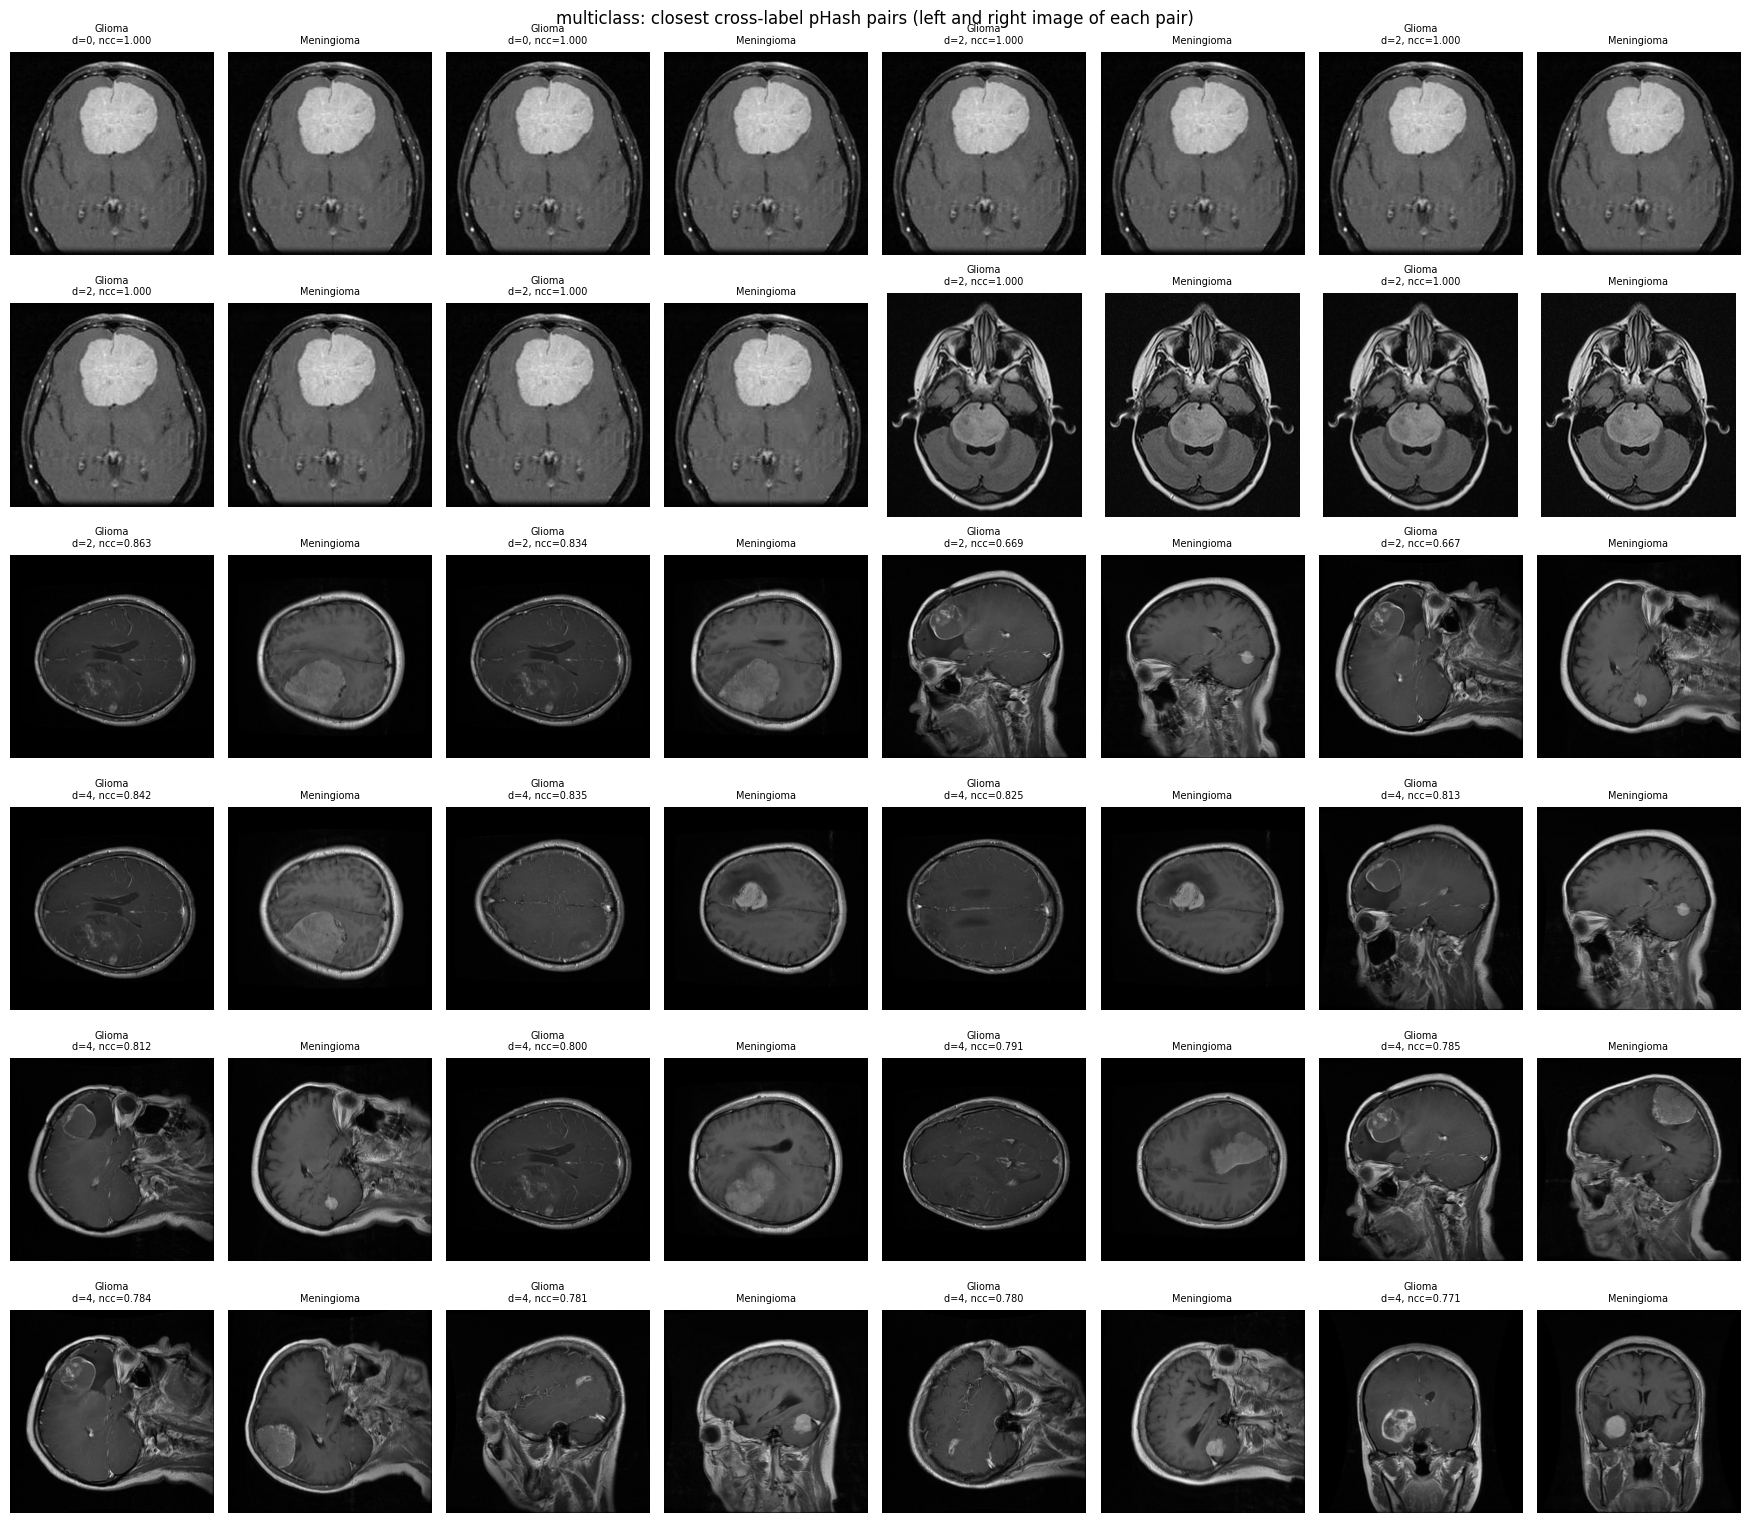

,class_name,before,original_pass_kept,label_aware_kept
0,Glioma,2352,2000,1998
1,Meningioma,1645,1304,1310
2,Pituitary,1831,1401,1401


,split,class_name,images
0,removed,Meningioma,8
1,train,Glioma,2


[10:12:13] {'multiclass_removed_cross_label': 23, 'binary_cross_label_pairs': 0, 'binary_cross_label_by_category': {}, 'binary_label_conflict_images': 0, 'binary_label_aware_kept': {'No Tumor': 459, 'Tumor': 728}, 'multiclass_cross_label_pairs': 31, 'multiclass_cross_label_by_category': {'visually distinct (hash false positive)': 23, 'near-identical (label conflict)': 8}, 'multiclass_label_conflict_images': 10, 'multiclass_label_aware_kept': {'Glioma': 1998, 'Meningioma': 1310, 'Pituitary': 1401}}


In [11]:
def ncc_vectors(thumbs):
    vectors = thumbs.reshape(len(thumbs), -1).astype(np.float32)
    vectors -= vectors.mean(axis=1, keepdims=True)
    vectors /= np.linalg.norm(vectors, axis=1, keepdims=True) + 1e-8
    return vectors


NCC_VECTORS = {task: ncc_vectors(THUMBS[task]) for task in POOLS}


def cross_label_pairs(task, tolerance=HAMMING_TOLERANCE):
    frame, matrix = POOLS[task], DIST[task]
    first, second = np.nonzero(np.triu(matrix <= tolerance, k=1))
    labels = frame["label"].values
    conflict = labels[first] != labels[second]
    first, second = first[conflict], second[conflict]
    vectors = NCC_VECTORS[task]
    pairs = pd.DataFrame(
        {
            "index_a": first,
            "index_b": second,
            "class_a": frame["class_name"].values[first],
            "class_b": frame["class_name"].values[second],
            "source_a": frame["subset"].values[first],
            "source_b": frame["subset"].values[second],
            "split_a": frame["split"].values[first],
            "split_b": frame["split"].values[second],
            "key_a": frame["key"].values[first],
            "key_b": frame["key"].values[second],
            "hamming": matrix[first, second].astype(int),
            "ncc": (vectors[first] * vectors[second]).sum(axis=1),
        }
    )
    pairs["category"] = np.where(
        pairs["ncc"] >= NCC_DUPLICATE,
        "near-identical (label conflict)",
        "visually distinct (hash false positive)",
    )
    return pairs.sort_values(["hamming", "ncc"], ascending=[True, False]).reset_index(drop=True)


def pair_gallery(task, pairs, name):
    shown = pairs.head(GALLERY_PAIRS)
    if shown.empty:
        log(f"{task}: no cross-label pairs to show")
        return
    columns = 4
    rows = math.ceil(len(shown) / columns)
    fig, axes = plt.subplots(
        rows, columns * 2, figsize=(2.2 * columns * 2, 2.6 * rows), squeeze=False
    )
    for axis in axes.flat:
        axis.axis("off")
    for position, pair in enumerate(shown.itertuples()):
        row, column = divmod(position, columns)
        for offset, (index, label) in enumerate(
            [(pair.index_a, pair.class_a), (pair.index_b, pair.class_b)]
        ):
            axis = axes[row, column * 2 + offset]
            with Image.open(POOLS[task]["path"].iloc[index]) as img:
                axis.imshow(img.convert("L"), cmap="gray")
            axis.set_title(
                f"{label}\nd={pair.hamming}, ncc={pair.ncc:.3f}" if offset == 0 else label,
                fontsize=7,
            )
    fig.suptitle(f"{task}: closest cross-label pHash pairs (left and right image of each pair)")
    fig.tight_layout()
    save_fig(fig, name)


def label_aware_counts(task, pairs):
    frame = POOLS[task]
    conflicted = set(
        pairs.loc[
            pairs["category"].str.startswith("near-identical"), ["index_a", "index_b"]
        ].values.ravel()
    )
    valid = VALID[task].copy()
    valid[list(conflicted)] = False
    keep, _, _ = greedy_dedup(DIST[task], valid, HAMMING_TOLERANCE, labels=frame["label"].values)
    return keep, conflicted


CROSS_LABEL = {}
for task in POOLS:
    pairs = cross_label_pairs(task)
    CROSS_LABEL[task] = pairs
    save_table(pairs, f"{task}_cross_label_pairs", show=False)
    summary = pairs.groupby(["class_a", "class_b", "category"]).size().rename("pairs").reset_index()
    save_table(summary, f"{task}_cross_label_summary")
    pair_gallery(task, pairs, f"02_{task}_cross_label_gallery")

    keep_aware, conflicted = label_aware_counts(task, pairs)
    frame = POOLS[task]
    original_keep = MC_KEEP if task == "multiclass" else np.ones(len(frame), dtype=bool)
    comparison = pd.DataFrame(
        {
            "class_name": CLASS_NAMES[task],
            "before": [
                int((frame["label"] == label).sum()) for label in range(len(CLASS_NAMES[task]))
            ],
            "original_pass_kept": [
                int((original_keep & (frame["label"] == label)).sum())
                for label in range(len(CLASS_NAMES[task]))
            ],
            "label_aware_kept": [
                int((keep_aware & (frame["label"] == label)).sum())
                for label in range(len(CLASS_NAMES[task]))
            ],
        }
    )
    save_table(comparison, f"{task}_label_aware_dedup_counts")

    conflicted_frame = frame.iloc[sorted(conflicted)] if conflicted else frame.iloc[[]]
    placement = (
        conflicted_frame.groupby(["split", "class_name"]).size().rename("images").reset_index()
    )
    save_table(placement, f"{task}_label_conflict_images_by_split")

    RESULTS[f"{task}_cross_label_pairs"] = int(len(pairs))
    RESULTS[f"{task}_cross_label_by_category"] = pairs["category"].value_counts().to_dict()
    RESULTS[f"{task}_label_conflict_images"] = int(len(conflicted))
    RESULTS[f"{task}_label_aware_kept"] = dict(
        zip(comparison["class_name"], comparison["label_aware_kept"])
    )

    test_conflicts = set(conflicted_frame.loc[conflicted_frame["split"] == "test", "key"])
    rows = []
    for run in RUNS.loc[RUNS["task"] == task, "run"]:
        if run in PREDICTIONS and test_conflicts:
            hits = PREDICTIONS[run]["test"][PREDICTIONS[run]["test"]["key"].isin(test_conflicts)]
            rows.append(
                {
                    "run": run,
                    "conflicting_test_images": len(hits),
                    "accuracy_on_them": hits["correct"].mean(),
                }
            )
    if rows:
        save_table(pd.DataFrame(rows), f"{task}_label_conflict_test_predictions")
log({key: value for key, value in RESULTS.items() if "cross_label" in key or "label_" in key})

## 12. The same pHash pass on the binary track

The paper did not deduplicate the binary pool. This cell runs the identical greedy pass on the 3,253 binary images, using the same hash, threshold and collection order. It reports, per source and class, how many images would survive, and whether each removal is within-source or cross-source and same-label or cross-label.

The nine binary models are **not** retrained on the deduplicated pool, because that needs retraining. Section 15 estimates its effect from the stored predictions instead.

In [12]:
binary = POOLS["binary"]
BIN_KEEP, BIN_NEAREST, _ = greedy_dedup(DIST["binary"], VALID["binary"], HAMMING_TOLERANCE)
binary_survival = (
    binary.assign(kept=BIN_KEEP)
    .groupby(["subset", "class_name"], sort=False)
    .agg(before=("kept", "size"), after=("kept", "sum"))
    .reset_index()
)
binary_survival["removed"] = binary_survival["before"] - binary_survival["after"]
binary_survival["removed_pct"] = (
    100 * binary_survival["removed"] / binary_survival["before"]
).round(2)
save_table(binary_survival, "binary_survival_by_source")

binary_removals = removal_breakdown("binary", BIN_KEEP, BIN_NEAREST)
binary_types = pd.crosstab(
    [binary_removals["source"], binary_removals["kept_partner_source"]],
    [binary_removals["origin"], binary_removals["label"]],
    margins=True,
)
display(binary_types)
binary_types.reset_index().to_csv(METRICS / "binary_removal_types.csv", index=False)

RESULTS["binary_dedup_kept"] = int(BIN_KEEP.sum())
RESULTS["binary_dedup_removed"] = int((~BIN_KEEP & VALID["binary"]).sum())
RESULTS["binary_dedup_removed_pct"] = round(100 * RESULTS["binary_dedup_removed"] / len(binary), 2)
RESULTS["binary_dedup_kept_by_class"] = binary.loc[BIN_KEEP, "class_name"].value_counts().to_dict()
RESULTS["binary_removed_cross_source"] = int((binary_removals["origin"] == "cross-source").sum())
RESULTS["binary_removed_cross_label"] = int((binary_removals["label"] == "cross-label").sum())
log({key: value for key, value in RESULTS.items() if key.startswith("binary_")})

,subset,class_name,before,after,removed,removed_pct
0,Chakrabarty,No Tumor,98,76,22,22.45
1,Br35H,No Tumor,1500,383,1117,74.47
2,Chakrabarty,Tumor,155,130,25,16.13
3,Br35H,Tumor,1500,598,902,60.13


origin                          cross-source within-source   All
label                             same-label    same-label      
source      kept_partner_source                                 
Br35H       Br35H                          0          1288  1288
            Chakrabarty                  731             0   731
Chakrabarty Chakrabarty                    0            47    47
All                                      731          1335  2066

[10:12:14] {'binary_cross_label_pairs': 0, 'binary_cross_label_by_category': {}, 'binary_label_conflict_images': 0, 'binary_label_aware_kept': {'No Tumor': 459, 'Tumor': 728}, 'binary_dedup_kept': 1187, 'binary_dedup_removed': 2066, 'binary_dedup_removed_pct': 63.51, 'binary_dedup_kept_by_class': {'Tumor': 728, 'No Tumor': 459}, 'binary_removed_cross_source': 731, 'binary_removed_cross_label': 0}


## 13. Is a Hamming threshold of 5 adequate? An independent duplicate detector

pHash can produce false positives, where distinct images collide, and false negatives, where the same image is missed after a crop or intensity change. As an independent check, this cell treats two images as the same image when their 64x64 normalised thumbnails correlate at NCC >= 0.98. This follows the detector used by Vangala et al. (2026), cited in the paper.

For each Hamming threshold it reports:
- how many NCC duplicates pHash catches (recall);
- how many pHash pairs are not NCC duplicates;
- how many pairs each detector flags.

The NCC matrix is computed on the GPU. Expected output: a table and a recall plot, the evidence for or against the threshold of 5.

NCC binary:   0%|          | 0/4 [00:00<?, ?it/s]

NCC multiclass:   0%|          | 0/6 [00:00<?, ?it/s]

,task,hamming_threshold,ncc_duplicate_pairs,phash_pairs,ncc_pairs_caught_by_phash,phash_recall_of_ncc_pairs,phash_pairs_not_ncc_duplicates
0,binary,0,6078,2299,2244,0.369200,55
1,binary,1,6078,2299,2244,0.369200,55
2,binary,2,6078,4644,4324,0.711418,320
3,binary,3,6078,4644,4324,0.711418,320
4,binary,4,6078,6398,5412,0.890424,986
5,binary,5,6078,6398,5412,0.890424,986
6,binary,6,6078,7734,5839,0.960678,1895
7,binary,7,6078,7734,5839,0.960678,1895
8,binary,8,6078,8867,6038,0.993419,2829
9,binary,9,6078,8867,6038,0.993419,2829


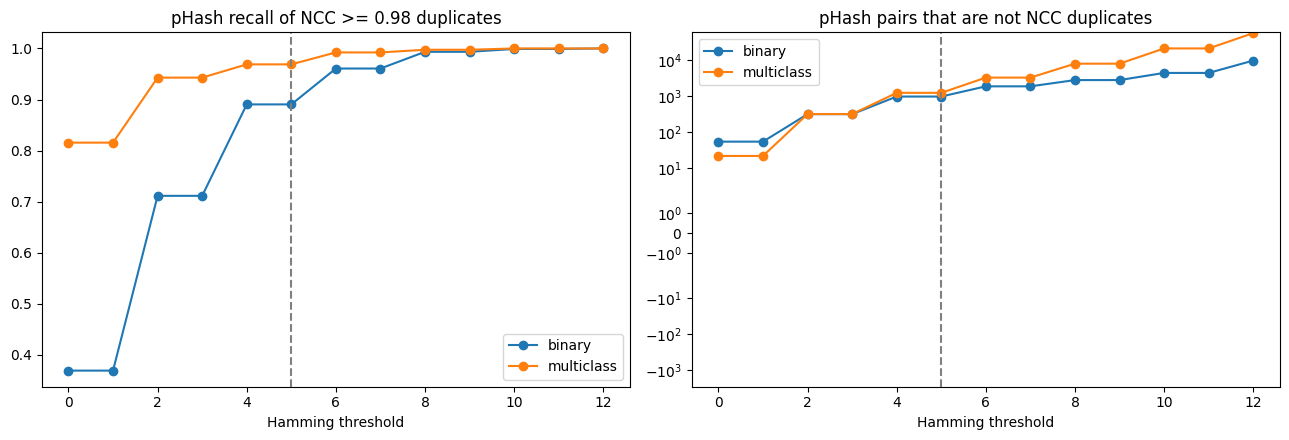

In [13]:
def ncc_pairs(task):
    vectors = torch.from_numpy(NCC_VECTORS[task]).to(DEVICES[0])
    rows, cols = [], []
    for start in tqdm(range(0, len(vectors), 1024), desc=f"NCC {task}"):
        block = vectors[start : start + 1024] @ vectors.T
        hit = (block >= NCC_DUPLICATE).nonzero()
        first, second = hit[:, 0] + start, hit[:, 1]
        keep = first < second
        rows.append(first[keep].cpu().numpy())
        cols.append(second[keep].cpu().numpy())
    del vectors
    torch.cuda.empty_cache()
    return np.concatenate(rows), np.concatenate(cols)


detector_rows = []
for task in POOLS:
    first, second = ncc_pairs(task)
    valid_pair = VALID[task][first] & VALID[task][second]
    first, second = first[valid_pair], second[valid_pair]
    ncc_distances = DIST[task][first, second]
    for threshold in THRESHOLDS:
        caught = int((ncc_distances <= threshold).sum())
        hash_pairs = int(PAIRS_WITHIN[task][threshold])
        detector_rows.append(
            {
                "task": task,
                "hamming_threshold": threshold,
                "ncc_duplicate_pairs": len(first),
                "phash_pairs": hash_pairs,
                "ncc_pairs_caught_by_phash": caught,
                "phash_recall_of_ncc_pairs": caught / len(first) if len(first) else np.nan,
                "phash_pairs_not_ncc_duplicates": hash_pairs - caught,
            }
        )
detector = pd.DataFrame(detector_rows)
save_table(detector, "phash_vs_ncc_detector")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for task, group in detector.groupby("task"):
    axes[0].plot(
        group["hamming_threshold"], group["phash_recall_of_ncc_pairs"], marker="o", label=task
    )
    axes[1].plot(
        group["hamming_threshold"], group["phash_pairs_not_ncc_duplicates"], marker="o", label=task
    )
for axis, title in zip(
    axes, ["pHash recall of NCC >= 0.98 duplicates", "pHash pairs that are not NCC duplicates"]
):
    axis.axvline(HAMMING_TOLERANCE, color="grey", linestyle="--")
    axis.set(title=title, xlabel="Hamming threshold")
    axis.legend()
axes[1].set_yscale("symlog")
fig.tight_layout()
save_fig(fig, "03_phash_vs_ncc")
at_tolerance = detector[detector["hamming_threshold"] == HAMMING_TOLERANCE].set_index("task")
RESULTS["phash_recall_at_5"] = at_tolerance["phash_recall_of_ncc_pairs"].round(4).to_dict()
RESULTS["phash_pairs_not_ncc_at_5"] = at_tolerance["phash_pairs_not_ncc_duplicates"].to_dict()

## 14. Train-test leakage audit

For every test and validation image, this cell finds the smallest Hamming distance to any image in the training split the models actually used, and the largest thumbnail NCC with any training image.
- In the multiclass track, deduplication guarantees a distance above 5, so leakage can only appear above that threshold.
- In the binary track there was no deduplication, so this measures how many test images had a near-twin in training.

Expected output: the share of test images with a training near-duplicate at each threshold, and histograms of the nearest-training distance.

,task,hamming_threshold,test_images,with_train_near_duplicate,share_pct
0,binary,0,488,245,50.20
1,binary,1,488,245,50.20
2,binary,2,488,363,74.39
3,binary,3,488,363,74.39
4,binary,4,488,403,82.58
5,binary,5,488,403,82.58
6,binary,6,488,425,87.09
7,binary,7,488,425,87.09
8,binary,8,488,441,90.37
9,binary,9,488,441,90.37


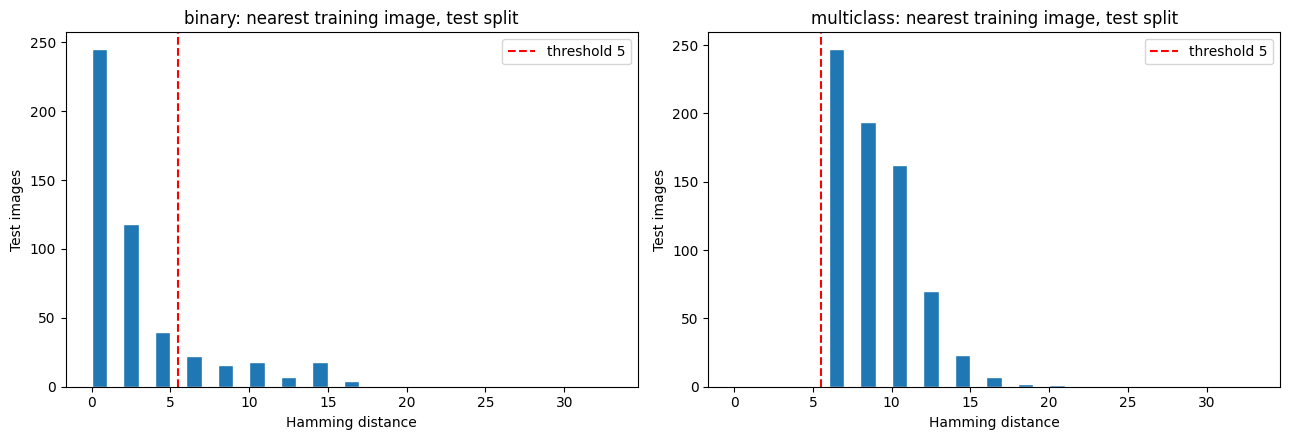

In [14]:
LEAKAGE = {}
leak_rows = []
for task, frame in POOLS.items():
    train_index = np.flatnonzero(frame["split"].values == "train")
    train_vectors = torch.from_numpy(NCC_VECTORS[task][train_index]).to(DEVICES[0])
    parts = []
    for split_name in ("val", "test"):
        index = np.flatnonzero(frame["split"].values == split_name)
        min_distance = DIST[task][np.ix_(index, train_index)].min(axis=1)
        query = torch.from_numpy(NCC_VECTORS[task][index]).to(DEVICES[0])
        max_ncc = (query @ train_vectors.T).max(dim=1).values.cpu().numpy()
        parts.append(
            pd.DataFrame(
                {
                    "key": frame["key"].values[index],
                    "split": split_name,
                    "label": frame["label"].values[index],
                    "source": frame["subset"].values[index],
                    "min_hamming_to_train": min_distance,
                    "max_ncc_to_train": max_ncc,
                }
            )
        )
    del train_vectors
    torch.cuda.empty_cache()
    LEAKAGE[task] = pd.concat(parts, ignore_index=True)
    save_table(LEAKAGE[task], f"{task}_leakage_per_image", show=False)
    test = LEAKAGE[task][LEAKAGE[task]["split"] == "test"]
    for threshold in THRESHOLDS:
        leak_rows.append(
            {
                "task": task,
                "hamming_threshold": threshold,
                "test_images": len(test),
                "with_train_near_duplicate": int((test["min_hamming_to_train"] <= threshold).sum()),
            }
        )
    leak_rows.append(
        {
            "task": task,
            "hamming_threshold": f"NCC>={NCC_DUPLICATE}",
            "test_images": len(test),
            "with_train_near_duplicate": int((test["max_ncc_to_train"] >= NCC_DUPLICATE).sum()),
        }
    )
leakage_table = pd.DataFrame(leak_rows)
leakage_table["share_pct"] = (
    100 * leakage_table["with_train_near_duplicate"] / leakage_table["test_images"]
).round(2)
save_table(leakage_table, "train_test_leakage_by_threshold")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, (task, frame) in zip(axes, LEAKAGE.items()):
    test = frame[frame["split"] == "test"]
    axis.hist(test["min_hamming_to_train"], bins=range(0, 34), color="tab:blue", edgecolor="white")
    axis.axvline(
        HAMMING_TOLERANCE + 0.5, color="red", linestyle="--", label=f"threshold {HAMMING_TOLERANCE}"
    )
    axis.set(
        title=f"{task}: nearest training image, test split",
        xlabel="Hamming distance",
        ylabel="Test images",
    )
    axis.legend()
fig.tight_layout()
save_fig(fig, "04_train_test_nearest_distance")
for task in POOLS:
    row = leakage_table[
        (leakage_table["task"] == task) & (leakage_table["hamming_threshold"] == HAMMING_TOLERANCE)
    ].iloc[0]
    RESULTS[f"{task}_test_with_train_near_duplicate_at_5"] = (
        f"{row.with_train_near_duplicate}/{row.test_images} ({row.share_pct}%)"
    )

## 15. Threshold sensitivity: pool size and test accuracy on leakage-free subsets

This addresses the paper's claim that it "reports how sensitive the resulting accuracies are to the deduplication threshold", without retraining.
- **(a) Pool size.** The greedy pass is rerun at every threshold from 0 to 12, and the images it would keep are counted per class for both tracks.
- **(b) Test accuracy.** For every run with stored predictions, accuracy is recomputed on the test images whose nearest training image is farther than the threshold, alongside the number of images left. A final column uses the NCC detector instead.

For the binary track, the threshold-5 column is the best available estimate of what the nine binary models would score on a test set free of near-duplicates. It is a proxy for retraining on a deduplicated pool, not the same thing: the training pool still contains the duplicates.

Greedy pass per threshold (binary):   0%|          | 0/13 [00:00<?, ?it/s]

Greedy pass per threshold (multiclass):   0%|          | 0/13 [00:00<?, ?it/s]

,task,hamming_threshold,kept,removed,kept_No Tumor,kept_Tumor,kept_Glioma,kept_Meningioma,kept_Pituitary
0,binary,0,2077,1176,860.0,1217.0,NaN,NaN,NaN
1,binary,1,2077,1176,860.0,1217.0,NaN,NaN,NaN
2,binary,2,1497,1756,583.0,914.0,NaN,NaN,NaN
3,binary,3,1497,1756,583.0,914.0,NaN,NaN,NaN
4,binary,4,1187,2066,459.0,728.0,NaN,NaN,NaN
5,binary,5,1187,2066,459.0,728.0,NaN,NaN,NaN
6,binary,6,998,2255,397.0,601.0,NaN,NaN,NaN
7,binary,7,998,2255,397.0,601.0,NaN,NaN,NaN
8,binary,8,882,2371,344.0,538.0,NaN,NaN,NaN
9,binary,9,882,2371,344.0,538.0,NaN,NaN,NaN


,model,task,full_test_accuracy,acc_t5,n_t5,acc_t8,n_t8,acc_t10,n_t10,acc_ncc_clean,n_ncc_clean
0,CoAtNet-0,binary,0.9939,0.9882,85,0.9787,47,1.0000,29,0.9891,92
1,DenseNet121,binary,0.9939,0.9765,85,0.9574,47,1.0000,29,0.9783,92
2,EfficientNetB0,binary,0.9939,0.9647,85,0.9362,47,0.9310,29,0.9674,92
3,InceptionV3,binary,0.9877,0.9529,85,0.9149,47,0.9310,29,0.9565,92
4,MobileNetV3-Large,binary,0.9078,0.8000,85,0.7447,47,0.7586,29,0.8043,92
5,ResNet50,binary,0.9939,0.9647,85,0.9362,47,0.9655,29,0.9674,92
6,Swin-Base,binary,0.9590,0.8941,85,0.8936,47,0.9310,29,0.9022,92
7,VGG16,binary,0.8832,0.8235,85,0.7234,47,0.7241,29,0.7935,92
8,ViT-B/16,binary,0.9488,0.9176,85,0.8936,47,0.8966,29,0.9239,92
9,CoAtNet-0,multiclass,0.9844,0.9844,706,0.9736,265,0.9903,103,0.9844,703


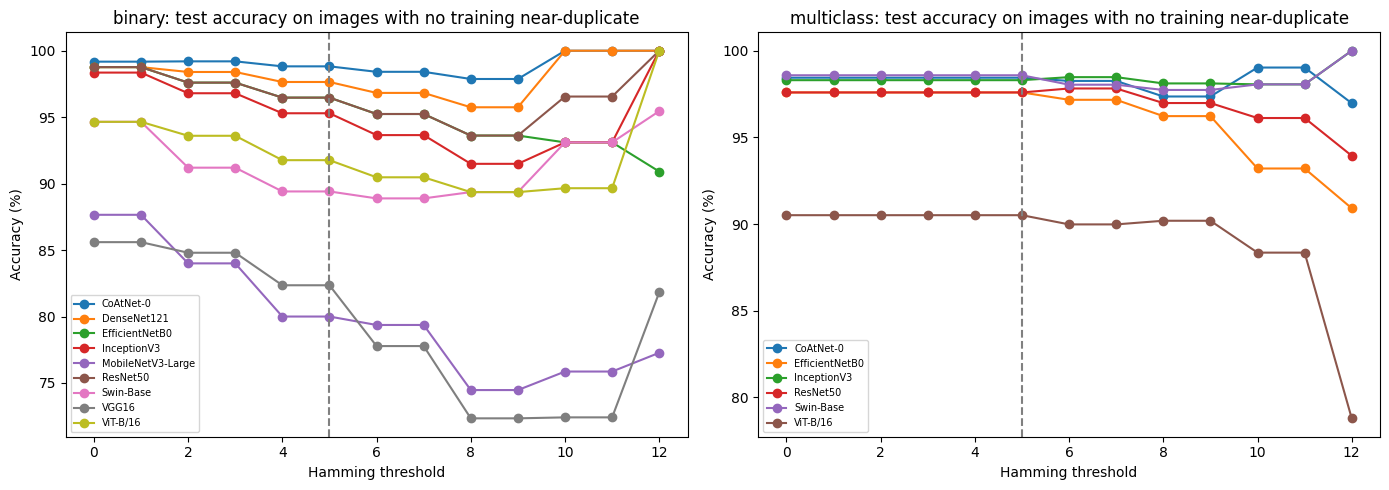

In [15]:
pool_rows = []
for task, frame in POOLS.items():
    for threshold in tqdm(THRESHOLDS, desc=f"Greedy pass per threshold ({task})"):
        keep, _, _ = greedy_dedup(DIST[task], VALID[task], threshold)
        row = {
            "task": task,
            "hamming_threshold": threshold,
            "kept": int(keep.sum()),
            "removed": int((~keep & VALID[task]).sum()),
        }
        row.update(
            {
                f"kept_{name}": int((keep & (frame["class_name"] == name)).sum())
                for name in CLASS_NAMES[task]
            }
        )
        pool_rows.append(row)
pool_sensitivity = pd.DataFrame(pool_rows)
save_table(pool_sensitivity, "dedup_pool_size_by_threshold")

accuracy_rows = []
for run, frames in PREDICTIONS.items():
    task = RUNS.set_index("run").loc[run, "task"]
    merged = frames["test"].merge(
        LEAKAGE[task][LEAKAGE[task]["split"] == "test"], on="key", how="left"
    )
    row = {
        "run": run,
        "task": task,
        "model": RUNS.set_index("run").loc[run, "model"],
        "full_test_accuracy": merged["correct"].mean(),
        "full_test_images": len(merged),
    }
    for threshold in THRESHOLDS:
        subset = merged[merged["min_hamming_to_train"] > threshold]
        row[f"acc_t{threshold}"] = subset["correct"].mean() if len(subset) else np.nan
        row[f"n_t{threshold}"] = len(subset)
    ncc_clean = merged[merged["max_ncc_to_train"] < NCC_DUPLICATE]
    row["acc_ncc_clean"] = ncc_clean["correct"].mean() if len(ncc_clean) else np.nan
    row["n_ncc_clean"] = len(ncc_clean)
    accuracy_rows.append(row)

if accuracy_rows:
    accuracy_sensitivity = pd.DataFrame(accuracy_rows)
    save_table(accuracy_sensitivity, "test_accuracy_by_threshold", show=False)
    shown = [
        "model",
        "task",
        "full_test_accuracy",
        "acc_t5",
        "n_t5",
        "acc_t8",
        "n_t8",
        "acc_t10",
        "n_t10",
        "acc_ncc_clean",
        "n_ncc_clean",
    ]
    display(accuracy_sensitivity[shown].round(4))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for axis, task in zip(axes, ["binary", "multiclass"]):
        for row in accuracy_sensitivity[accuracy_sensitivity["task"] == task].itertuples():
            axis.plot(
                THRESHOLDS,
                [100 * getattr(row, f"acc_t{t}") for t in THRESHOLDS],
                marker="o",
                label=row.model,
            )
        axis.axvline(HAMMING_TOLERANCE, color="grey", linestyle="--")
        axis.set(
            title=f"{task}: test accuracy on images with no training near-duplicate",
            xlabel="Hamming threshold",
            ylabel="Accuracy (%)",
        )
        axis.legend(fontsize=7)
    fig.tight_layout()
    save_fig(fig, "05_accuracy_by_threshold")
    RESULTS["accuracy_full_vs_t5"] = {
        row.run: f"{100 * row.full_test_accuracy:.2f} -> {100 * row.acc_t5:.2f} (n={row.n_t5})"
        for row in accuracy_sensitivity.itertuples()
    }
else:
    log(
        "No stored predictions attached: accuracy sensitivity skipped (pool-size sensitivity still reported)."
    )

## 16. Test-image cache and brain masks

This cell prepares inputs for the model analyses.
- **Image cache.** Every test image is resized exactly as the evaluation transform did (`transforms.Resize((S, S))` on the RGB image), at 224 and 299 pixels (299 for InceptionV3), and cached in RAM as `uint8`.
- **Brain mask.** A mask is computed from each resized greyscale image as the reviewer proposed: Otsu threshold, a small closing, the largest connected component, then hole filling. On these 2D slices this captures the head (brain and skull), so "outside the mask" means background, borders and framing.

Expected output: mask coverage statistics per task and class, and a quality-check figure with mask contours. Inspect it before trusting section 19.

Caching binary test images at 224px:   0%|          | 0/488 [00:00<?, ?it/s]

Caching binary test images at 299px:   0%|          | 0/488 [00:00<?, ?it/s]

Caching multiclass test images at 224px:   0%|          | 0/706 [00:00<?, ?it/s]

Caching multiclass test images at 299px:   0%|          | 0/706 [00:00<?, ?it/s]

,task,size,class_name,images,mask_area_mean,mask_area_sd
0,binary,224,No Tumor,240,0.5179,0.1291
1,binary,224,Tumor,248,0.6087,0.1595
2,binary,299,No Tumor,240,0.5093,0.1304
3,binary,299,Tumor,248,0.5998,0.1664
4,multiclass,224,Glioma,300,0.4716,0.0949
5,multiclass,224,Meningioma,196,0.4661,0.1045
6,multiclass,224,Pituitary,210,0.6091,0.0943
7,multiclass,299,Glioma,300,0.4700,0.0952
8,multiclass,299,Meningioma,196,0.4647,0.1037
9,multiclass,299,Pituitary,210,0.6032,0.0965


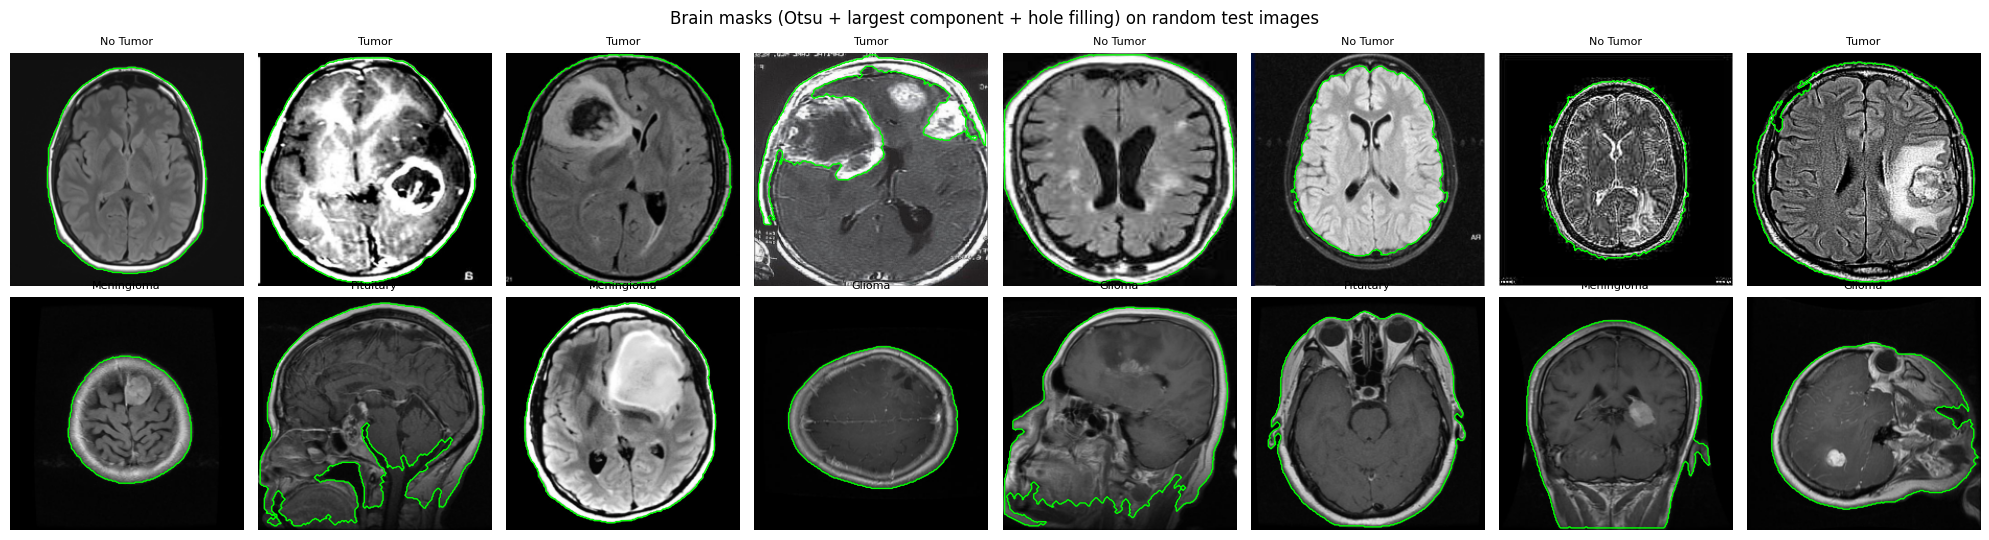

In [16]:
def head_mask(gray):
    try:
        foreground = gray > threshold_otsu(gray)
    except ValueError:
        return np.ones_like(gray, dtype=bool)
    foreground = ndimage.binary_closing(foreground, iterations=2)
    labels, count = ndimage.label(foreground)
    if count == 0:
        return np.ones_like(gray, dtype=bool)
    sizes = ndimage.sum(foreground, labels, range(1, count + 1))
    return ndimage.binary_fill_holes(labels == int(np.argmax(sizes)) + 1)


def load_resized(args):
    path, size = args
    with Image.open(path) as img:
        rgb = transforms.Resize((size, size))(img.convert("RGB"))
    return np.asarray(rgb, dtype=np.uint8), head_mask(np.asarray(rgb.convert("L"), dtype=np.uint8))


TEST_CACHE = {}
for task, frame in POOLS.items():
    test = frame[frame["split"] == "test"].reset_index(drop=True)
    for size in sorted(set(RUNS.loc[RUNS["task"] == task, "img_size"])):
        with concurrent.futures.ProcessPoolExecutor(max_workers=N_JOBS) as pool:
            loaded = list(
                tqdm(
                    pool.map(load_resized, [(path, size) for path in test["path"]], chunksize=8),
                    total=len(test),
                    desc=f"Caching {task} test images at {size}px",
                )
            )
        TEST_CACHE[(task, size)] = {
            "keys": test["key"].values,
            "labels": test["label"].values,
            "images": np.stack([item[0] for item in loaded]),
            "masks": np.stack([item[1] for item in loaded]),
        }

coverage = []
for (task, size), cache in TEST_CACHE.items():
    area = cache["masks"].reshape(len(cache["masks"]), -1).mean(axis=1)
    for label, name in enumerate(CLASS_NAMES[task]):
        selected = area[cache["labels"] == label]
        coverage.append(
            {
                "task": task,
                "size": size,
                "class_name": name,
                "images": len(selected),
                "mask_area_mean": selected.mean(),
                "mask_area_sd": selected.std(),
            }
        )
save_table(pd.DataFrame(coverage).round(4), "brain_mask_coverage")

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 8, figsize=(20, 5.5))
for row, task in enumerate(["binary", "multiclass"]):
    cache = TEST_CACHE[(task, 224)]
    for axis, index in zip(axes[row], rng.choice(len(cache["images"]), size=8, replace=False)):
        axis.imshow(cache["images"][index])
        axis.contour(cache["masks"][index], levels=[0.5], colors="lime", linewidths=1)
        axis.set_title(CLASS_NAMES[task][cache["labels"][index]], fontsize=8)
        axis.axis("off")
fig.suptitle("Brain masks (Otsu + largest component + hole filling) on random test images")
fig.tight_layout()
save_fig(fig, "06_brain_mask_quality_check")

## 17. Model builders and checkpoint discovery

`build_model` rebuilds each run's architecture without pretrained weights, so no download is needed. It replaces the head exactly as the training notebook did, including the details that change parameter names and shapes:
- the binary ViT replaces `heads`, and the multiclass ViT replaces `heads.head`;
- the binary InceptionV3 also replaces its auxiliary head, while the multiclass one keeps an unused 1000-class auxiliary head;
- InceptionV3 uses `transform_input=True`, as its pretrained weights set it;
- Swin-Base comes from `timm` for the binary task and `torchvision` for the multiclass task.

It also returns the Grad-CAM target layer the paper used, plus, for Swin-Base, the final normalisation layer as an alternative target for the layer-sensitivity check.

Discovery loads every `.pth` or `.pt` file under `/kaggle/input` (as tensors only, `weights_only=True`). It assigns a file to a run when every parameter name and shape matches, so a binary checkpoint can never be confused with a multiclass one. Expected output: a table of runs with their checkpoint, or "not found".

In [17]:
def build_model(arch, task):
    outputs = 1 if task == "binary" else 3
    alternative = None
    if arch == "coatnet0":
        model = timm.create_model("coatnet_0_rw_224", pretrained=False)
        model.reset_classifier(num_classes=outputs)
        target = lambda net: net.stages[-1]
    elif arch == "densenet121":
        model = densenet121(weights=None)
        model.classifier = nn.Linear(model.classifier.in_features, outputs)
        target = lambda net: net.features[-1]
    elif arch == "efficientnetb0":
        model = efficientnet_b0(weights=None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, outputs)
        target = lambda net: net.features[-1]
    elif arch == "resnet50":
        model = resnet50(weights=None)
        model.fc = nn.Linear(model.fc.in_features, outputs)
        target = lambda net: net.layer4[-1]
    elif arch == "inceptionv3":
        model = inception_v3(
            weights=None, aux_logits=True, init_weights=False, transform_input=True
        )
        model.fc = nn.Linear(model.fc.in_features, outputs)
        if task == "binary":
            model.AuxLogits.fc = nn.Linear(model.AuxLogits.fc.in_features, 1)
        else:
            model.aux_logits = False
        target = lambda net: net.Mixed_7c
    elif arch == "mobilenetv3":
        model = mobilenet_v3_large(weights=None)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, outputs)
        target = lambda net: net.features[-1]
    elif arch == "vgg16":
        model = vgg16(weights=None)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, outputs)
        target = lambda net: net.features[-1]
    elif arch == "vit":
        model = vit_b_16(weights=None)
        if task == "binary":
            model.heads = nn.Linear(model.heads.head.in_features, 1)
        else:
            model.heads.head = nn.Linear(model.heads.head.in_features, 3)
        target = lambda net: net.encoder.layers[-1].ln_1
    elif arch == "swin_timm":
        model = timm.create_model(
            "swin_base_patch4_window7_224", pretrained=False, num_classes=outputs
        )
        target = lambda net: net.layers[-1].blocks[-1].norm1
        alternative = lambda net: net.norm
    elif arch == "swin_tv":
        model = swin_b(weights=None)
        model.head = nn.Linear(model.head.in_features, outputs)
        target = lambda net: net.features[-1][-1].norm1
        alternative = lambda net: net.norm
    else:
        raise ValueError(arch)
    return model, target, alternative


def tensor_state(obj):
    if isinstance(obj, dict) and isinstance(obj.get("state_dict"), dict):
        obj = obj["state_dict"]
    if not isinstance(obj, dict):
        return None
    return {
        (key[7:] if key.startswith("module.") else key): value
        for key, value in obj.items()
        if torch.is_tensor(value)
    }


PARAM_SHAPES = {}
for row in tqdm(list(RUNS.itertuples()), desc="Building architectures for shape matching"):
    model, _, _ = build_model(row.arch, row.task)
    PARAM_SHAPES[row.run] = {name: tuple(param.shape) for name, param in model.named_parameters()}
    del model

CHECKPOINTS = {}
candidates = sorted(
    set(INPUT.rglob("*.pth")) | set(INPUT.rglob("*.pt")),
    key=lambda path: (not path.name.startswith("final"), str(path)),
)
for path in tqdm(candidates, desc="Matching checkpoints"):
    try:
        state = tensor_state(torch.load(path, map_location="cpu", weights_only=True))
    except Exception as exc:
        log(f"Skipping {path}: {exc}")
        continue
    if not state:
        continue
    shapes = {key: tuple(value.shape) for key, value in state.items()}
    for run, expected in PARAM_SHAPES.items():
        if run not in CHECKPOINTS and all(
            shapes.get(name) == shape for name, shape in expected.items()
        ):
            CHECKPOINTS[run] = path
    del state

checkpoint_table = RUNS[["run", "model", "task"]].assign(
    checkpoint=RUNS["run"].map(lambda run: str(CHECKPOINTS.get(run, "not found")))
)
save_table(checkpoint_table, "checkpoint_discovery")
RESULTS["runs_with_checkpoint"] = sorted(CHECKPOINTS)

Building architectures for shape matching:   0%|          | 0/15 [00:00<?, ?it/s]

Matching checkpoints:   0%|          | 0/2 [00:00<?, ?it/s]

,run,model,task,checkpoint
0,binary-detection-coatnet0,CoAtNet-0,binary,not found
1,binary-detection-densenet121,DenseNet121,binary,not found
2,binary-detection-efficientnetb0,EfficientNetB0,binary,/kaggle/input/datasets/parthmital/revision-aud...
3,binary-detection-resnet50,ResNet50,binary,not found
4,binary-detection-inceptionv3,InceptionV3,binary,not found
5,binary-detection-swinbase,Swin-Base,binary,not found
6,binary-detection-vit-b16,ViT-B/16,binary,not found
7,binary-detection-mobilenetv3-large,MobileNetV3-Large,binary,not found
8,binary-detection-vgg16,VGG16,binary,not found
9,classification-swinbase,Swin-Base,multiclass,not found


## 18. Analysis functions: batched Grad-CAM, attention rollout, masked inference

- **`gradcam_batch`** reproduces the paper's Grad-CAM for a batch in fp32, which is the same per image because the models run in eval mode. It explains the predicted class, using the logit for "tumour" and its negative for "no tumour" in the binary track. Gradients are averaged spatially, the weighted activations go through a ReLU, are upsampled bilinearly, and each map is min-max normalised. Token and channels-last activations are converted to a spatial grid exactly as in the training notebooks.
- **`outside_fraction`** is the share of total map energy that falls outside the brain mask.
- **`vit_rollout`** computes attention rollout (Abnar and Zuidema, 2020) for the torchvision ViT-B/16. Each layer's attention is averaged over heads, the identity is added for the residual path, rows are renormalised, the layers are multiplied, and the class-token row gives the map. The attention modules are temporarily patched to return their weights. Rollout is not defined for Swin's shifted windows, so Swin is checked by changing the target layer instead.
- **`run_job`** loads one checkpoint on one GPU and processes the whole test set. It records each image's prediction on the original, background-only and brain-only image, and the outside-mask fraction for the paper's Grad-CAM layer, the alternative Swin layer and ViT rollout.

In [18]:
MEAN_T = {device: torch.tensor(MEAN, device=device).view(1, 3, 1, 1) for device in DEVICES}
STD_T = {device: torch.tensor(STD, device=device).view(1, 3, 1, 1) for device in DEVICES}


def to_input(images, device):
    tensor = torch.from_numpy(images).to(device).permute(0, 3, 1, 2).float().div_(255)
    return (tensor - MEAN_T[device]) / STD_T[device]


def to_nchw(tensor):
    if tensor.dim() == 3:  # transformer tokens: (batch, tokens, channels)
        tokens = tensor.shape[1]
        side = int(round(math.sqrt(tokens)))
        if side * side != tokens:  # drop the class token
            tensor = tensor[:, 1:, :]
            side = int(round(math.sqrt(tensor.shape[1])))
        return tensor.reshape(tensor.shape[0], side, side, tensor.shape[2]).permute(0, 3, 1, 2)
    if (
        tensor.dim() == 4
        and tensor.shape[1] == tensor.shape[2]
        and tensor.shape[3] != tensor.shape[1]
    ):
        return tensor.permute(0, 3, 1, 2)  # channels-last feature map
    return tensor


def normalise_maps(maps):
    maps = maps - maps.flatten(1).min(dim=1).values[:, None, None]
    peak = maps.flatten(1).max(dim=1).values[:, None, None]
    return torch.where(peak > 0, maps / peak.clamp_min(1e-12), maps)


def gradcam_batch(model, layer, inputs, binary):
    store = {}

    def hook(module, args, output):
        output = output[0] if isinstance(output, (tuple, list)) else output
        store["activation"] = output
        output.register_hook(lambda grad: store.__setitem__("gradient", grad))

    handle = layer.register_forward_hook(hook)
    try:
        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = model(inputs).float()
            if binary:
                predicted = (logits[:, 0] > 0).long()
                score = torch.where(predicted == 1, logits[:, 0], -logits[:, 0])
            else:
                predicted = logits.argmax(dim=1)
                score = logits.gather(1, predicted[:, None])[:, 0]
            score.sum().backward()
    finally:
        handle.remove()
    activation = to_nchw(store["activation"].detach().float())
    gradient = to_nchw(store["gradient"].detach().float())
    cam = F.relu((gradient.mean(dim=(2, 3), keepdim=True) * activation).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=inputs.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    model.zero_grad(set_to_none=True)
    return normalise_maps(cam), predicted


def vit_rollout(model, inputs):
    attentions, patched = [], []
    for block in model.encoder.layers:
        module, original = block.self_attention, block.self_attention.forward

        def forward(query, key, value, _original=original, **kwargs):
            kwargs["need_weights"], kwargs["average_attn_weights"] = True, False
            output, weights = _original(query, key, value, **kwargs)
            attentions.append(weights.detach().float())
            return output, weights

        module.forward = forward
        patched.append(module)
    try:
        with torch.no_grad():
            model(inputs)
    finally:
        for module in patched:
            del module.forward
    tokens = attentions[0].shape[-1]
    identity = torch.eye(tokens, device=inputs.device)
    rollout = identity.expand(inputs.shape[0], tokens, tokens).clone()
    for attention in attentions:
        attention = 0.5 * attention.mean(dim=1) + 0.5 * identity
        rollout = (attention / attention.sum(dim=-1, keepdim=True)) @ rollout
    side = int(math.sqrt(tokens - 1))
    maps = rollout[:, 0, 1:].reshape(-1, 1, side, side)
    maps = F.interpolate(maps, size=inputs.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    return normalise_maps(maps)


def outside_fraction(maps, masks):
    total = maps.flatten(1).sum(dim=1)
    outside = (maps * (~masks)).flatten(1).sum(dim=1)
    return torch.where(total > 0, outside / total, torch.full_like(total, float("nan")))


def predict(model, inputs, binary):
    with torch.no_grad(), torch.amp.autocast("cuda", dtype=torch.float16):
        logits = model(inputs).float()
    return (logits[:, 0] > 0).long() if binary else logits.argmax(dim=1)


def run_job(row, device):
    start = time.perf_counter()
    binary = row.task == "binary"
    cache = TEST_CACHE[(row.task, row.img_size)]
    model, target, alternative = build_model(row.arch, row.task)
    state = tensor_state(torch.load(CHECKPOINTS[row.run], map_location="cpu", weights_only=True))
    missing, unexpected = model.load_state_dict(state, strict=False)
    del state
    model = model.to(device).eval()
    results = {
        name: []
        for name in (
            "pred_original",
            "pred_background_only",
            "pred_brain_only",
            "cam_outside",
            "cam_outside_alt_layer",
            "rollout_outside",
        )
    }
    for begin in range(0, len(cache["images"]), GRADCAM_BATCH):
        images = cache["images"][begin : begin + GRADCAM_BATCH]
        masks_np = cache["masks"][begin : begin + GRADCAM_BATCH]
        masks = torch.from_numpy(masks_np).to(device)
        inputs = to_input(images, device)
        results["pred_original"].append(predict(model, inputs, binary).cpu())
        results["pred_background_only"].append(
            predict(model, to_input(images * (~masks_np)[..., None], device), binary).cpu()
        )
        results["pred_brain_only"].append(
            predict(model, to_input(images * masks_np[..., None], device), binary).cpu()
        )
        cam, _ = gradcam_batch(model, target(model), inputs, binary)
        results["cam_outside"].append(outside_fraction(cam, masks).cpu())
        if alternative is not None:
            cam_alt, _ = gradcam_batch(model, alternative(model), inputs, binary)
            results["cam_outside_alt_layer"].append(outside_fraction(cam_alt, masks).cpu())
        if row.arch == "vit":
            results["rollout_outside"].append(
                outside_fraction(vit_rollout(model, inputs), masks).cpu()
            )
    frame = pd.DataFrame(
        {
            "key": cache["keys"],
            "label": cache["labels"],
            "mask_area": cache["masks"].reshape(len(cache["masks"]), -1).mean(axis=1),
        }
    )
    for name, parts in results.items():
        frame[name] = torch.cat(parts).numpy() if parts else np.nan
    frame.insert(0, "run", row.run)
    del model
    torch.cuda.empty_cache()
    elapsed = time.perf_counter() - start
    log(
        f"{row.run} on {device}: {len(frame)} images in {elapsed:.1f}s ({len(frame) / elapsed:.1f} img/s), "
        f"peak {torch.cuda.max_memory_allocated(device) / 1024**3:.2f} GB, "
        f"missing keys {len(missing)}, unexpected keys {len(unexpected)}"
    )
    return frame

## 19. Run the model analyses on both GPUs

Every run with a checkpoint goes onto a shared queue. Two worker threads, one per GPU, take runs from it until it is empty, so both GPUs stay busy and the larger models are spread across them. The progress bar advances as each run finishes, and every run logs its time, throughput and peak memory.

The results are then checked and summarised:
- **Sanity check.** Each reloaded checkpoint's predictions on the original test images are compared with the stored predictions. Agreement should be about 100%, which confirms that the right checkpoint, preprocessing and split were used.
- **Grad-CAM outside the brain.** The outside-mask energy fraction is given as mean and SD per model and class, for all test images and for correct predictions only. For reference, a map spread evenly over the image would put a fraction equal to 1 minus the mask area outside.
- **Layer sensitivity and rollout.** The Swin-Base fraction is compared across its two target layers, and ViT-B/16 Grad-CAM is compared with rollout (Spearman correlation per image).

Model analyses (2 GPUs):   0%|          | 0/2 [00:00<?, ?it/s]

[10:13:53] classification-efficientnetb0 on cuda:0: 706 images in 51.7s (13.7 img/s), peak 2.32 GB, missing keys 0, unexpected keys 0
[10:13:57] binary-detection-efficientnetb0 on cuda:1: 488 images in 55.9s (8.7 img/s), peak 2.30 GB, missing keys 0, unexpected keys 0


,run,reloaded_accuracy,stored_accuracy,prediction_agreement
0,binary-detection-efficientnetb0,0.9939,0.9939,1.0
1,classification-efficientnetb0,0.9759,0.9759,1.0


,task,model,class_name,images,cam_outside_all,cam_outside_correct,uniform_map_outside,cam_outside_alt_layer,rollout_outside
0,binary,EfficientNetB0,No Tumor,240,0.068 ± 0.118,0.067 ± 0.117,0.482 ± 0.129,n/a,n/a
1,binary,EfficientNetB0,Tumor,248,0.077 ± 0.118,0.077 ± 0.118,0.391 ± 0.160,n/a,n/a
2,multiclass,EfficientNetB0,Glioma,300,0.040 ± 0.020,0.038 ± 0.018,0.528 ± 0.095,n/a,n/a
3,multiclass,EfficientNetB0,Meningioma,196,0.090 ± 0.044,0.091 ± 0.044,0.534 ± 0.105,n/a,n/a
4,multiclass,EfficientNetB0,Pituitary,210,0.092 ± 0.110,0.091 ± 0.109,0.391 ± 0.095,n/a,n/a


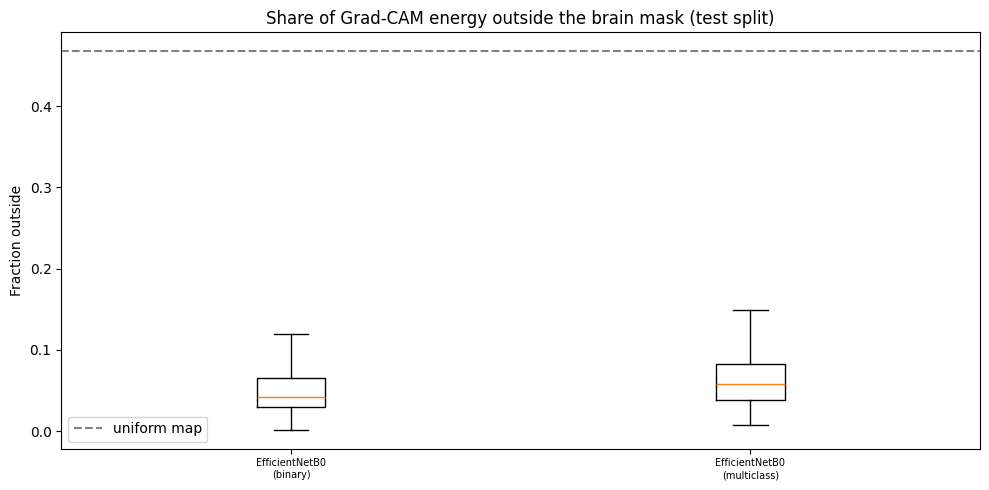

In [19]:
available = [row for row in RUNS.itertuples() if row.run in CHECKPOINTS]
JOB_FRAMES = []
if available:
    jobs = queue.Queue()
    for row in sorted(
        available,
        key=lambda item: -sum(math.prod(shape) for shape in PARAM_SHAPES[item.run].values()),
    ):
        jobs.put(row)
    lock = threading.Lock()
    bar = tqdm(total=len(available), desc="Model analyses (2 GPUs)")

    def worker(device):
        while True:
            try:
                row = jobs.get_nowait()
            except queue.Empty:
                return
            try:
                frame = run_job(row, device)
                with lock:
                    JOB_FRAMES.append(frame)
            except Exception as exc:
                log(f"{row.run} failed on {device}: {exc!r}")
            with lock:
                bar.update(1)

    threads = [threading.Thread(target=worker, args=(device,)) for device in DEVICES[:2]]
    for thread in threads:
        thread.start()
    for thread in threads:
        thread.join()
    bar.close()
else:
    log("No checkpoints attached: sections 19 and 20 are skipped.")

if JOB_FRAMES:
    PER_IMAGE = pd.concat(JOB_FRAMES, ignore_index=True).merge(
        RUNS[["run", "task", "model"]], on="run"
    )
    PER_IMAGE["class_name"] = [
        CLASS_NAMES[task][label] for task, label in zip(PER_IMAGE["task"], PER_IMAGE["label"])
    ]
    PER_IMAGE["correct"] = PER_IMAGE["pred_original"] == PER_IMAGE["label"]
    save_table(PER_IMAGE, "model_analyses_per_image", show=False)

    sanity = []
    for run, group in PER_IMAGE.groupby("run"):
        row = {"run": run, "reloaded_accuracy": group["correct"].mean()}
        if run in PREDICTIONS:
            stored = PREDICTIONS[run]["test"].set_index("key")
            row["stored_accuracy"] = stored["correct"].mean()
            row["prediction_agreement"] = (
                group.set_index("key")["pred_original"]
                == stored.loc[group["key"], "pred_label"].values
            ).mean()
        sanity.append(row)
    save_table(pd.DataFrame(sanity).round(4), "checkpoint_sanity_check")

    def mean_sd(values):
        values = values.dropna()
        return f"{values.mean():.3f} ± {values.std():.3f}" if len(values) else "n/a"

    rows = []
    for (task, model_name, class_name), group in PER_IMAGE.groupby(["task", "model", "class_name"]):
        correct = group[group["correct"]]
        rows.append(
            {
                "task": task,
                "model": model_name,
                "class_name": class_name,
                "images": len(group),
                "cam_outside_all": mean_sd(group["cam_outside"]),
                "cam_outside_correct": mean_sd(correct["cam_outside"]),
                "uniform_map_outside": mean_sd(1 - group["mask_area"]),
                "cam_outside_alt_layer": mean_sd(group["cam_outside_alt_layer"]),
                "rollout_outside": mean_sd(group["rollout_outside"]),
            }
        )
    outside_summary = pd.DataFrame(rows)
    save_table(outside_summary, "gradcam_outside_brain_fraction")

    per_model = PER_IMAGE.groupby(["task", "model"])["cam_outside"].agg(["mean", "std"]).round(3)
    RESULTS["gradcam_outside_fraction_mean_sd"] = {
        f"{task} {model_name}": f"{row['mean']} ± {row['std']}"
        for (task, model_name), row in per_model.iterrows()
    }

    swin = PER_IMAGE[PER_IMAGE["cam_outside_alt_layer"].notna()]
    if not swin.empty:
        layer_table = (
            swin.groupby(["task", "class_name"])
            .agg(
                paper_layer=("cam_outside", "mean"),
                final_norm_layer=("cam_outside_alt_layer", "mean"),
            )
            .round(3)
            .reset_index()
        )
        save_table(layer_table, "swin_target_layer_sensitivity")
    vit = PER_IMAGE[PER_IMAGE["rollout_outside"].notna()]
    for task, group in vit.groupby("task"):
        rho = spearmanr(
            group["cam_outside"], group["rollout_outside"], nan_policy="omit"
        ).correlation
        RESULTS[f"vit_{task}_gradcam_vs_rollout_spearman"] = round(float(rho), 3)

    order = PER_IMAGE.groupby(["task", "model"]).size().index.tolist()
    fig, axis = plt.subplots(figsize=(max(10, 1.1 * len(order)), 5))
    axis.boxplot(
        [
            PER_IMAGE[(PER_IMAGE["task"] == t) & (PER_IMAGE["model"] == m)]["cam_outside"].dropna()
            for t, m in order
        ],
        showfliers=False,
    )
    axis.set_xticks(range(1, len(order) + 1), [f"{m}\n({t})" for t, m in order])
    axis.axhline(
        (1 - PER_IMAGE["mask_area"]).mean(), color="grey", linestyle="--", label="uniform map"
    )
    axis.set(
        title="Share of Grad-CAM energy outside the brain mask (test split)",
        ylabel="Fraction outside",
    )
    axis.tick_params(axis="x", labelsize=7)
    axis.legend()
    fig.tight_layout()
    save_fig(fig, "07_gradcam_outside_brain")

## 20. Inference-only masking test

The reviewer's background-only ablation retrains each model on images whose brain region is set to zero. That needs retraining and is skipped. This cell instead gives an inference-only proxy using the trained models:
- **Background only:** the brain region is set to zero, leaving background, borders and framing.
- **Brain only:** the background is set to zero.

The two cases show different things.
- If a model still beats chance on **background-only** images, it is reading information outside the brain, which directly shows a shortcut.
- A drop to chance does **not** rule out a shortcut, because background-only images are far from the training distribution. Only the retraining ablation can settle that.

Chance level is shown as the majority-class rate of the test split. Expected output: an accuracy table per model and condition, and a bar chart.

,task,model,images,original,background_only,brain_only,chance_majority
0,binary,EfficientNetB0,488,0.9939,0.5574,0.9775,0.5082
1,multiclass,EfficientNetB0,706,0.9759,0.3697,0.9660,0.4249


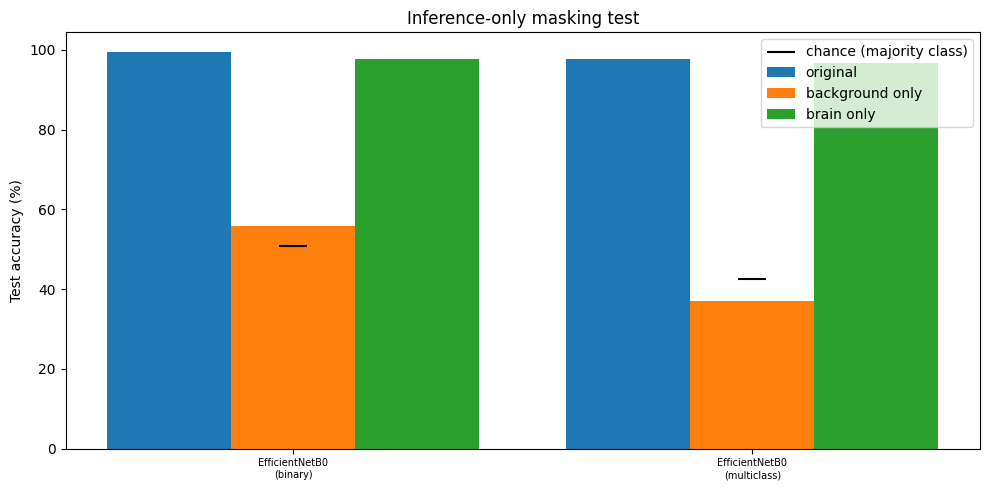

In [20]:
if JOB_FRAMES:
    masking_rows = []
    for (task, model_name), group in PER_IMAGE.groupby(["task", "model"]):
        masking_rows.append(
            {
                "task": task,
                "model": model_name,
                "images": len(group),
                "original": (group["pred_original"] == group["label"]).mean(),
                "background_only": (group["pred_background_only"] == group["label"]).mean(),
                "brain_only": (group["pred_brain_only"] == group["label"]).mean(),
                "chance_majority": group["label"].value_counts(normalize=True).max(),
            }
        )
    masking = pd.DataFrame(masking_rows).round(4)
    save_table(masking, "masking_test_accuracy")
    RESULTS["background_only_accuracy"] = {
        f"{row.task} {row.model}": f"{100 * row.background_only:.1f}% (chance {100 * row.chance_majority:.1f}%)"
        for row in masking.itertuples()
    }
    fig, axis = plt.subplots(figsize=(max(10, 1.1 * len(masking)), 5))
    positions = np.arange(len(masking))
    for offset, column in zip([-0.27, 0, 0.27], ["original", "background_only", "brain_only"]):
        axis.bar(
            positions + offset, 100 * masking[column], width=0.27, label=column.replace("_", " ")
        )
    axis.scatter(
        positions,
        100 * masking["chance_majority"],
        color="black",
        marker="_",
        s=400,
        label="chance (majority class)",
        zorder=3,
    )
    axis.set_xticks(
        positions, [f"{row.model}\n({row.task})" for row in masking.itertuples()], fontsize=7
    )
    axis.set(ylabel="Test accuracy (%)", title="Inference-only masking test")
    axis.legend()
    fig.tight_layout()
    save_fig(fig, "08_masking_test")

## 21. Latency and throughput with a variance measure

This re-measures inference cost so that **both** latency and throughput can be reported as mean ± SD with a stated warm-up. The original notebooks kept no per-pass timings for throughput.

The protocol matches the original benchmark:
- one T4 (`cuda:0`), fp16 autocast, a synthetic input at each model's native size, and device synchronisation before each timer read;
- latency: 10 untimed warm-up passes, then 100 timed single-image passes;
- throughput: 3 warm-up passes, then 20 timed passes at batch size 32, with throughput computed per pass.

The whole protocol is repeated three times per run, and the SD across repeats is reported next to the within-run SD. Random weights are used because compute cost does not depend on weight values. Runs are measured one after another, never alongside other GPU work. The paper's single-run figures are shown for comparison.

Benchmarking on cuda:0:   0%|          | 0/15 [00:00<?, ?it/s]

[10:14:11] binary-detection-coatnet0: latency 11.27 ± 0.41 ms, throughput 575 ± 4 img/s (last repeat)
[10:14:21] binary-detection-densenet121: latency 17.00 ± 0.70 ms, throughput 704 ± 15 img/s (last repeat)
[10:14:37] binary-detection-efficientnetb0: latency 9.00 ± 0.33 ms, throughput 1630 ± 13 img/s (last repeat)
[10:14:42] binary-detection-resnet50: latency 6.61 ± 0.26 ms, throughput 818 ± 4 img/s (last repeat)
[10:14:51] binary-detection-inceptionv3: latency 12.45 ± 0.46 ms, throughput 562 ± 3 img/s (last repeat)
[10:15:11] binary-detection-swinbase: latency 24.14 ± 0.63 ms, throughput 213 ± 2 img/s (last repeat)
[10:15:21] binary-detection-vit-b16: latency 7.59 ± 0.38 ms, throughput 347 ± 3 img/s (last repeat)
[10:15:31] binary-detection-mobilenetv3-large: latency 7.19 ± 0.20 ms, throughput 2648 ± 74 img/s (last repeat)
[10:15:41] binary-detection-vgg16: latency 4.60 ± 0.07 ms, throughput 396 ± 2 img/s (last repeat)
[10:16:03] classification-swinbase: latency 27.42 ± 0.71 ms, thro

,run,model,task,latency_ms,latency_within_sd,latency_between_repeats_sd,throughput,throughput_within_sd,throughput_between_repeats_sd,paper_latency_ms,paper_throughput
0,binary-detection-coatnet0,CoAtNet-0,binary,11.57,0.43,0.25,577.54,3.09,2.62,13.91,520.34
1,binary-detection-densenet121,DenseNet121,binary,16.72,0.95,0.25,707.22,6.97,2.65,19.43,629.80
2,binary-detection-efficientnetb0,EfficientNetB0,binary,8.94,0.35,0.05,1636.50,19.54,7.24,10.76,1364.24
3,binary-detection-resnet50,ResNet50,binary,6.58,0.23,0.06,819.07,4.23,1.85,7.35,771.21
4,binary-detection-inceptionv3,InceptionV3,binary,12.30,0.40,0.29,564.48,3.22,2.03,14.05,514.15
5,binary-detection-swinbase,Swin-Base,binary,24.00,0.55,0.23,214.94,1.33,1.59,28.99,195.63
6,binary-detection-vit-b16,ViT-B/16,binary,7.41,0.60,0.27,350.56,2.98,3.57,8.80,286.88
7,binary-detection-mobilenetv3-large,MobileNetV3-Large,binary,7.10,0.32,0.25,2664.56,58.95,17.67,8.08,2408.52
8,binary-detection-vgg16,VGG16,binary,4.56,0.06,0.04,397.30,2.21,1.92,8.18,338.15
9,classification-swinbase,Swin-Base,multiclass,27.76,1.17,0.63,204.80,1.23,1.63,35.13,202.41


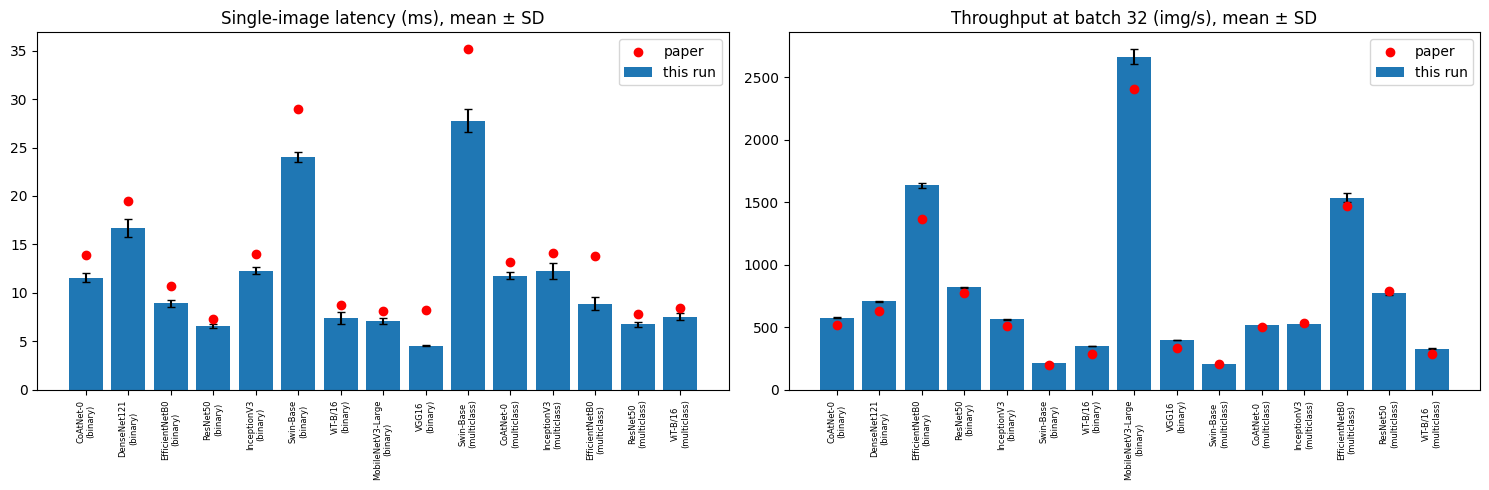

In [21]:
def time_passes(model, inputs, warmup, iterations, device):
    with torch.no_grad(), torch.amp.autocast("cuda", dtype=torch.float16):
        for _ in range(warmup):
            model(inputs)
        torch.cuda.synchronize(device)
        timings = []
        for _ in range(iterations):
            start = time.perf_counter()
            model(inputs)
            torch.cuda.synchronize(device)
            timings.append(time.perf_counter() - start)
    return np.array(timings)


device = DEVICES[0]
bench_rows = []
for row in tqdm(list(RUNS.itertuples()), desc="Benchmarking on cuda:0"):
    model, _, _ = build_model(row.arch, row.task)
    model = model.to(device).eval()
    single = torch.randn(1, 3, row.img_size, row.img_size, device=device)
    batch = torch.randn(THR_BATCH, 3, row.img_size, row.img_size, device=device)
    for repeat in range(BENCH_REPEATS):
        latency = time_passes(model, single, LAT_WARMUP, LAT_ITERS, device) * 1000
        throughput = THR_BATCH / time_passes(model, batch, THR_WARMUP, THR_ITERS, device)
        bench_rows.append(
            {
                "run": row.run,
                "model": row.model,
                "task": row.task,
                "repeat": repeat + 1,
                "latency_mean_ms": latency.mean(),
                "latency_sd_ms": latency.std(ddof=1),
                "latency_median_ms": np.median(latency),
                "latency_p95_ms": np.percentile(latency, 95),
                "throughput_mean": throughput.mean(),
                "throughput_sd": throughput.std(ddof=1),
            }
        )
    log(
        f"{row.run}: latency {latency.mean():.2f} ± {latency.std(ddof=1):.2f} ms, "
        f"throughput {throughput.mean():.0f} ± {throughput.std(ddof=1):.0f} img/s (last repeat)"
    )
    del model, single, batch
    torch.cuda.empty_cache()

bench = pd.DataFrame(bench_rows)
save_table(bench.round(3), "efficiency_benchmark_repeats", show=False)
efficiency = (
    bench.groupby(["run", "model", "task"], sort=False)
    .agg(
        latency_ms=("latency_mean_ms", "mean"),
        latency_within_sd=("latency_sd_ms", "mean"),
        latency_between_repeats_sd=("latency_mean_ms", "std"),
        throughput=("throughput_mean", "mean"),
        throughput_within_sd=("throughput_sd", "mean"),
        throughput_between_repeats_sd=("throughput_mean", "std"),
    )
    .reset_index()
)
efficiency["paper_latency_ms"] = efficiency["run"].map(lambda run: PAPER_EFFICIENCY[run][0])
efficiency["paper_throughput"] = efficiency["run"].map(lambda run: PAPER_EFFICIENCY[run][1])
save_table(efficiency.round(2), "efficiency_with_variance")
RESULTS["efficiency_mean_sd"] = {
    row.run: f"latency {row.latency_ms:.1f} ± {row.latency_within_sd:.1f} ms, throughput {row.throughput:.0f} ± {row.throughput_within_sd:.0f} img/s"
    for row in efficiency.itertuples()
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
labels = [f"{row.model}\n({row.task})" for row in efficiency.itertuples()]
positions = np.arange(len(efficiency))
axes[0].bar(
    positions,
    efficiency["latency_ms"],
    yerr=efficiency["latency_within_sd"],
    capsize=3,
    label="this run",
)
axes[0].scatter(positions, efficiency["paper_latency_ms"], color="red", zorder=3, label="paper")
axes[1].bar(
    positions,
    efficiency["throughput"],
    yerr=efficiency["throughput_within_sd"],
    capsize=3,
    label="this run",
)
axes[1].scatter(positions, efficiency["paper_throughput"], color="red", zorder=3, label="paper")
for axis, title in zip(
    axes, ["Single-image latency (ms), mean ± SD", "Throughput at batch 32 (img/s), mean ± SD"]
):
    axis.set_xticks(positions, labels, fontsize=6, rotation=90)
    axis.set_title(title)
    axis.legend()
fig.tight_layout()
save_fig(fig, "09_efficiency_with_variance")

## 22. Summary of findings for the manuscript

Collects the headline numbers from every section into one table and saves them to `metrics/revision_audit_summary.json`, ready to paste into the paper. Sections that were skipped because their inputs were not attached (stored predictions or checkpoints) are listed as such.

In [22]:
RESULTS["splits_source"] = {task: SPLITS[task]["source"] for task in SPLITS}
RESULTS["runs_without_checkpoint"] = sorted(set(RUNS["run"]) - set(CHECKPOINTS))
RESULTS["runs_without_stored_predictions"] = sorted(set(RUNS["run"]) - set(PREDICTIONS))
RESULTS["skipped_requires_retraining"] = [
    "Retraining the nine binary models on the deduplicated pool (proxy: section 15)",
    "Background-only training ablation (proxy: section 20)",
]
save_json(RESULTS, "revision_audit_summary")
summary = pd.DataFrame(
    [
        {"finding": key, "value": json.dumps(value, default=str)[:300]}
        for key, value in RESULTS.items()
    ]
)
pd.set_option("display.max_colwidth", 300)
display(summary)

,finding,value
0,multiclass_dedup_reproduced,true
1,multiclass_removed_total,1123
2,multiclass_removed_cross_source,3
3,multiclass_removed_within_source,1120
4,multiclass_removed_cross_label,23
5,multiclass_survival_by_source,"{""Cheng"": {""before"": 3064, ""after"": 2568}, ""Testing"": {""before"": 289, ""after"": 212}, ""Training"": {""before"": 2475, ""after"": 1925}}"
6,binary_cross_label_pairs,0
7,binary_cross_label_by_category,{}
8,binary_label_conflict_images,0
9,binary_label_aware_kept,"{""No Tumor"": 459, ""Tumor"": 728}"


## 23. Package outputs

Zips everything in `/kaggle/working/` (plots, metrics, logs) into `outputs.zip`, after checking there is enough free disk, and shows a download link. After a saved run, the zip also appears in the notebook's Output tab.

In [23]:
ZIP_PATH = WORK / "outputs.zip"
EXCLUDE_PARTS = {"__pycache__", ".cache", ".ipynb_checkpoints", "cache", "tmp", "wandb"}
STORED_SUFFIXES = {
    ".zip",
    ".png",
    ".jpg",
    ".jpeg",
    ".pt",
    ".pth",
    ".bin",
    ".safetensors",
    ".gz",
    ".npz",
}

files = [
    path
    for path in WORK.rglob("*")
    if path.is_file()
    and path != ZIP_PATH
    and not EXCLUDE_PARTS.intersection(path.relative_to(WORK).parts)
]
total_bytes = sum(path.stat().st_size for path in files)
free_bytes = shutil.disk_usage(WORK).free
assert (
    free_bytes > total_bytes * 1.05
), f"Not enough disk space to zip {total_bytes / 1e9:.2f} GB with {free_bytes / 1e9:.2f} GB free."
with zipfile.ZipFile(ZIP_PATH, "w", allowZip64=True) as archive:
    for path in tqdm(files, desc="Zipping outputs", unit="file"):
        method = (
            zipfile.ZIP_STORED if path.suffix.lower() in STORED_SUFFIXES else zipfile.ZIP_DEFLATED
        )
        archive.write(path, path.relative_to(WORK), compress_type=method)
print(f"Zipped {len(files)} files ({total_bytes / 1e9:.2f} GB) into {ZIP_PATH}", flush=True)
display(FileLink(os.path.relpath(ZIP_PATH)))

Zipping outputs:   0%|          | 0/40 [00:00<?, ?file/s]

Zipped 40 files (0.01 GB) into /kaggle/working/outputs.zip


/kaggle/working/outputs.zip